**STEP 1 | Imports**

In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import geopandas as gpd
import rasterio
import os
import datetime
import ee
import seaborn as sns
import io
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, accuracy_score
from scipy.interpolate import griddata
from rasterio.transform import from_origin




STEP 2 | Load & Clean NO₂ Sensor Data

In [3]:
# Run this in your Anaconda terminal if packages are missing:
# pip install geopandas rasterio pykrige earthengine-api geemap
print('Packages ready')


Packages ready


In [4]:
import os

# ── Set the path to your air-quality CSV ─────────────────────────────────
DATA_DIR = r'C:\Users\farah\OneDrive\Bureau\Capstone'  # ← change if needed
AQ_FILE  = os.path.join(DATA_DIR, '201200-1-calidad-aire-horario-csv.csv')
STA_FILE = os.path.join(DATA_DIR, '212629-0-estaciones-control-aire-csv (1).csv')

df = pd.read_csv(AQ_FILE, sep=';')
print('Air quality data loaded:', df.shape)


Air quality data loaded: (55048, 56)


In [5]:
df = pd.read_csv('201200-1-calidad-aire-horario-csv.csv', sep=';')

# **DATASET — Air Quality Measurements**

**PROVINCIA**: Numeric code representing the province where the monitoring station is located.

**MUNICIPIO**: Numeric code representing the municipality (city or administrative area).

**ESTACION**: Identifier of the air quality monitoring station.

**MAGNITUD**: Code representing the pollutant being measured (e.g., NO₂, PM10, SO₂).


**PUNTO_MUESTREO**: Sampling point identifier. This is a composite code that uniquely identifies the monitoring station and pollutant combination.


**ANO**: Year in which the measurement was recorded.

**MES**: Month of measurement (1–12).

**DIA**: Day of the month when the measurement was recorded (1–31).

**H01**: Pollutant concentration measured between 00:00–01:00.

**V01**: Validation flag for H01 (indicates whether the value is valid, missing, or estimated).

**H02**: Pollutant concentration measured between 01:00–02:00.

**V02**: Validation flag for H02.

**H03**: Pollutant concentration measured between 02:00–03:00.

**V03**: Validation flag for H03.

(..)

**H24**: Pollutant concentration measured between 23:00–00:00.

**V24**: Validation flag for H24.

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 55048 entries, 0 to 55047
Data columns (total 56 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   PROVINCIA       55048 non-null  int64  
 1   MUNICIPIO       55048 non-null  int64  
 2   ESTACION        55048 non-null  int64  
 3   MAGNITUD        55048 non-null  int64  
 4   PUNTO_MUESTREO  55048 non-null  object 
 5   ANO             55048 non-null  int64  
 6   MES             55048 non-null  int64  
 7   DIA             55048 non-null  int64  
 8   H01             55048 non-null  float64
 9   V01             55048 non-null  object 
 10  H02             55048 non-null  float64
 11  V02             55048 non-null  object 
 12  H03             55048 non-null  float64
 13  V03             55048 non-null  object 
 14  H04             55048 non-null  float64
 15  V04             55048 non-null  object 
 16  H05             55048 non-null  float64
 17  V05             55048 non-null 

In [7]:
for col in df.columns:
    print(f"\nColumn: {col}")
    print(df[col].dropna().unique()[:10])


Column: PROVINCIA
[28]

Column: MUNICIPIO
[79]

Column: ESTACION
[11 16 17 18 24 27 35 36 38 39]

Column: MAGNITUD
[12 20 30 35  7  8 14 10  9  1]

Column: PUNTO_MUESTREO
['28079011_12_8' '28079011_20_59' '28079011_30_59' '28079011_35_59'
 '28079011_7_8' '28079011_8_8' '28079016_12_8' '28079016_14_6'
 '28079016_7_8' '28079016_8_8']

Column: ANO
[2025 2026]

Column: MES
[ 1  2  3  4  5  6  7  8  9 10]

Column: DIA
[ 1  2  3  4  5  6  7  8  9 10]

Column: H01
[ 30. 150.  17. 173.  68.  20.   9.  11.   8.  15.]

Column: V01
['V' 'N']

Column: H02
[ 46.  77.  26. 165.  70.  14.   5.  11.   7.   9.]

Column: V02
['V' 'N']

Column: H03
[ 65.  71.  26. 155.  32.  11.   5.   9.   4.   8.]

Column: V03
['V' 'N']

Column: H04
[60. 46. 40. 98. 14.  9.  5.  3.  4. 12.]

Column: V04
['V' 'N']

Column: H05
[44. 40. 36. 74. 10.  5.  8.  3. 42. 70.]

Column: V05
['V' 'N']

Column: H06
[22. 44. 73. 71. 11.  7.  5.  3.  6. 37.]

Column: V06
['V' 'N']

Column: H07
[ 21.  67. 113.  46.  18.   7.  11.  17

In [8]:
# Keep only NO₂ (MAGNITUD == 8)
dfNO2 = df[df['MAGNITUD'] == 8].copy()

In [9]:
# Hour and flag column names
hour_cols = [f'H{str(i).zfill(2)}' for i in range(1, 25)]
flag_cols = [f'V{str(i).zfill(2)}' for i in range(1, 25)]

In [10]:
# Replace invalid hourly values with NaN using flag columns
for i in range(1, 25):
    h, v = f'H{str(i).zfill(2)}', f'V{str(i).zfill(2)}'
    dfNO2.loc[dfNO2[v] != 'V', h] = np.nan


In [11]:
# Drop flag columns
dfNO2 = dfNO2.drop(columns=flag_cols)


In [12]:
# Compute daily mean (skip NaN hours)
dfNO2['NO2_daily_mean'] = dfNO2[hour_cols].mean(axis=1, skipna=True)
dfNO2['valid_hours']    = dfNO2[hour_cols].notna().sum(axis=1)


In [13]:
# Keep only days with at least 18 valid hours
dfNO2 = dfNO2[dfNO2['valid_hours'] >= 18]

In [14]:
# Build date column
dfNO2['date'] = pd.to_datetime(
    dfNO2[['ANO', 'MES', 'DIA']].rename(
        columns={'ANO': 'year', 'MES': 'month', 'DIA': 'day'}
    )
)


In [15]:
# Extract station code from PUNTO_MUESTREO
dfNO2['STATION_CODE'] = dfNO2['PUNTO_MUESTREO'].str.split('_').str[0].astype(int)


In [16]:
# Rename and drop unnecessary columns
dfNO2 = dfNO2.rename(columns={
    'ESTACION': 'STATION',
    'ANO': 'YEAR', 'MES': 'MONTH', 'DIA': 'DAY'
})

In [17]:
dfNO2 = dfNO2.drop(columns=[
    'PUNTO_MUESTREO', 'YEAR', 'MONTH', 'DAY',
    'MAGNITUD', 'PROVINCIA', 'MUNICIPIO'
] + hour_cols)


In [18]:
print("Sensor data shape:", dfNO2.shape)
print("Date range:", dfNO2['date'].min(), "→", dfNO2['date'].max())


Sensor data shape: (9892, 5)
Date range: 2025-01-01 00:00:00 → 2026-02-28 00:00:00


**STEP 3 | Load Station Metadata**

In [19]:
dfsta = pd.read_csv(STA_FILE, sep=';')
print('Station metadata loaded:', dfsta.shape)


Station metadata loaded: (24, 25)


In [20]:
dfsta = pd.read_csv('212629-0-estaciones-control-aire-csv (1).csv', sep=';')


**DATASET — Monitoring Stations Information**
**CODIGO**: Unique identifier assigned to each monitoring station.

**CODIGO_CORTO**: Short version of the station identifier used for simplified referencing.

**ESTACION**: Name of the air quality monitoring station.

**DIRECCION**: Physical address where the station is located.

**LONGITUD_ETRS89**: Longitude coordinate in the ETRS89 coordinate system.

**LATITUD_ETRS89**: Latitude coordinate in the ETRS89 coordinate system.

**ALTITUD**: Altitude of the station above sea level (in meters).

**COORDENADA_X_ETRS89**: Projected X coordinate in the ETRS89 system.

**COORDENADA_Y_ETRS89**: Projected Y coordinate in the ETRS89 system.

**LONGITUD**: Geographic longitude in decimal degrees (GPS format).

**LATITUD**: Geographic latitude in decimal degrees (GPS format).

**COD_TIPO**: Code representing the type of monitoring station.

**NOM_TIPO**: Description of the station type (e.g., urban, traffic, suburban, rural).

**NO2**: Indicates availability of nitrogen dioxide (NO₂) measurements.

**SO2**: Indicates availability of sulfur dioxide (SO₂) measurements.

**CO**: Indicates availability of carbon monoxide (CO) measurements.

**PM10**: Indicates availability of particulate matter ≤10 µm.

**PM2_5**: Indicates availability of particulate matter ≤2.5 µm.

**O3**: Indicates availability of ozone (O₃).

**BTX**: Indicates availability of benzene, toluene, and xylene measurements.

**COD_VIA**: Code representing the road or street associated with the station location.

**VIA_CLASE**: Type of road (e.g., street, avenue, boulevard).

**VIA_PAR**: Additional road information (e.g., numbering or section).

**VIA_NOMBRE**: Name of the road or street.

**Fecha alta**: Date when the station was installed or became operational.

In [21]:
# Keep only NO₂ stations
dfsta = dfsta[dfsta['NO2'] == 'X'].copy()
dfsta = dfsta[['CODIGO', 'ESTACION', 'LATITUD', 'LONGITUD',
               'COD_TIPO', 'ALTITUD', 'Fecha alta']].copy()


In [22]:
dfsta['Fecha alta'] = pd.to_datetime(dfsta['Fecha alta'], dayfirst=True)


In [23]:
dfsta = dfsta.rename(columns={
    'CODIGO'    : 'STATION_CODE',
    'ESTACION'  : 'STATION_NAME',
    'LATITUD'   : 'LATITUDE',
    'LONGITUD'  : 'LONGITUDE',
    'COD_TIPO'  : 'STATION_TYPE',
    'ALTITUD'   : 'ALTITUDE',
    'Fecha alta': 'INSTALLATION_DATE'
})

In [24]:
print("Station metadata shape:", dfsta.shape)

Station metadata shape: (24, 7)


 **STEP 4 | Merge Sensor + StationMetadata**

In [25]:
dffinal_merged = dfNO2.merge(dfsta, on='STATION_CODE', how='left')
print("Unmatched rows:", dffinal_merged['LATITUDE'].isna().sum())


Unmatched rows: 0


In [26]:
# Keep only records after station installation date
dffinal_merged = dffinal_merged[
    dffinal_merged['date'] >= dffinal_merged['INSTALLATION_DATE']
].copy()

In [27]:
# Drop columns no longer needed
dffinal_merged = dffinal_merged.drop(
    columns=['INSTALLATION_DATE', 'STATION']
)

print("Final merged shape:", dffinal_merged.shape)
print(dffinal_merged[['STATION_NAME', 'STATION_TYPE',
                       'NO2_daily_mean', 'date']].head())


Final merged shape: (9892, 9)
    STATION_NAME STATION_TYPE  NO2_daily_mean       date
0  Ramón y Cajal           UT       40.583333 2025-01-01
1  Ramón y Cajal           UT       46.833333 2025-01-02
2  Ramón y Cajal           UT       49.791667 2025-01-03
3  Ramón y Cajal           UT       45.000000 2025-01-04
4  Ramón y Cajal           UT       32.166667 2025-01-05


**STEP 5 | Build GeoDataFrame (UTM 30N)**

In [28]:
gdf = gpd.GeoDataFrame(
    dffinal_merged,
    geometry=gpd.points_from_xy(
        dffinal_merged['LONGITUDE'],
        dffinal_merged['LATITUDE']
    ),
    crs='EPSG:4326'
).to_crs('EPSG:25830')

print(gdf[['STATION_NAME', 'NO2_daily_mean', 'date', 'geometry']].head())



    STATION_NAME  NO2_daily_mean       date                        geometry
0  Ramón y Cajal       40.583333 2025-01-01  POINT (442564.049 4478088.586)
1  Ramón y Cajal       46.833333 2025-01-02  POINT (442564.049 4478088.586)
2  Ramón y Cajal       49.791667 2025-01-03  POINT (442564.049 4478088.586)
3  Ramón y Cajal       45.000000 2025-01-04  POINT (442564.049 4478088.586)
4  Ramón y Cajal       32.166667 2025-01-05  POINT (442564.049 4478088.586)


**STEP 6 | Select Day & Build Kriging Grid**

In [29]:
TARGET_DATE = '2025-01-14'

one_day = gdf[gdf['date'] == TARGET_DATE].copy()
print(f"Stations on {TARGET_DATE}: {len(one_day)}")

x = one_day.geometry.x.values        # easting  (metres, UTM 30N)
y = one_day.geometry.y.values        # northing (metres, UTM 30N)
z = one_day['NO2_daily_mean'].values  # NO₂ µg/m³

print(f"NO₂ range: {z.min():.1f} – {z.max():.1f} µg/m³")

# 100m resolution grid with 2km padding
resolution = 100
xi = np.arange(x.min() - 2000, x.max() + 2000, resolution)
yi = np.arange(y.min() - 2000, y.max() + 2000, resolution)
print(f"Grid size: {len(xi)} × {len(yi)} = {len(xi)*len(yi)} pixels")

Stations on 2025-01-14: 24
NO₂ range: 22.0 – 72.7 µg/m³
Grid size: 205 × 231 = 47355 pixels


**STEP 7 | Ordinary Kriging — Exponential Model**

In [30]:
# Run in terminal if needed:  pip install pykrige
print('pykrige ready')


pykrige ready


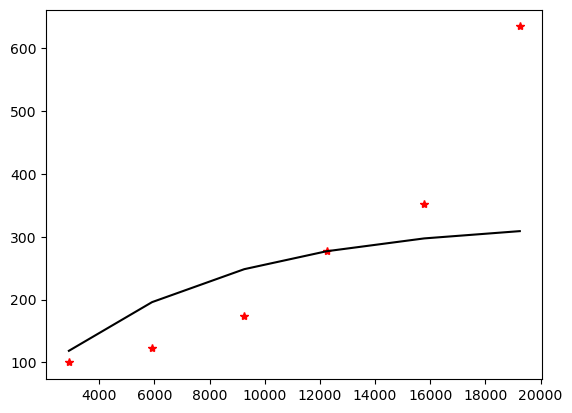

Map A → min: 22.13  max: 72.73 µg/m³
Map B → min: 0.70  max: 318.67


In [31]:
from pykrige.ok import OrdinaryKriging
ok = OrdinaryKriging(
    x, y, z,
    variogram_model='exponential',
    verbose=False,
    enable_plotting=True
)

z_grid, var_grid = ok.execute('grid', xi, yi)

print(f"Map A → min: {z_grid.min():.2f}  max: {z_grid.max():.2f} µg/m³")
print(f"Map B → min: {var_grid.min():.2f}  max: {var_grid.max():.2f}")


**STEP 8 | Plot Kriging Maps + Station Values**

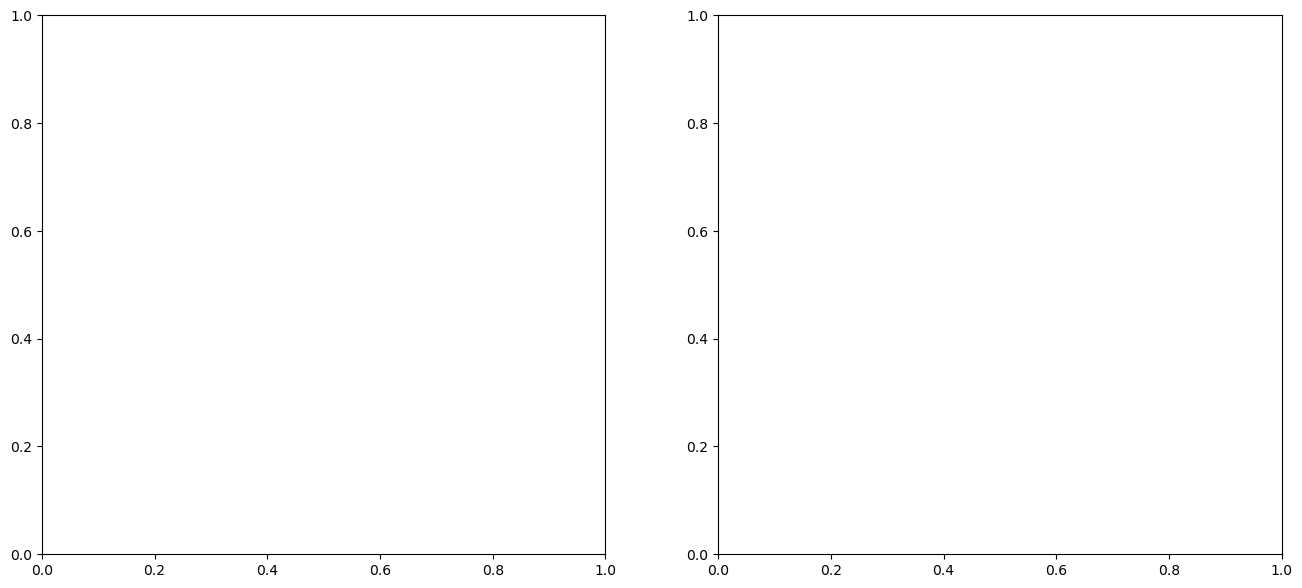

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

In [33]:
# --- Map A: Interpolated NO₂ ---
im1 = axes[0].contourf(xi, yi, z_grid, levels=20, cmap='YlOrRd')
axes[0].scatter(x, y, c=z, cmap='YlOrRd',
                edgecolors='black', linewidths=0.8, s=80, zorder=5)
plt.colorbar(im1, ax=axes[0], label='NO₂ (µg/m³)')
axes[0].set_title(f'Kriging NO₂ — Exponential — {TARGET_DATE}', fontsize=12)
axes[0].set_xlabel('Easting (m)')
axes[0].set_ylabel('Northing (m)')

# Station value labels
for _, row in one_day.iterrows():
    axes[0].annotate(
        f"{row['NO2_daily_mean']:.1f}",
        xy=(row.geometry.x, row.geometry.y),
        xytext=(4, 3), textcoords='offset points',
        fontsize=6.5, color='black',
        bbox=dict(boxstyle='round,pad=0.15',
                  facecolor='white', alpha=0.55, edgecolor='none')
    )

C:\Users\farah\AppData\Local\Temp\ipykernel_24092\1459163531.py:5: UserWarning: Adding colorbar to a different Figure <Figure size 1600x700 with 3 Axes> than <Figure size 640x480 with 0 Axes> which fig.colorbar is called on.
  plt.colorbar(im1, ax=axes[0], label='NO₂ (µg/m³)')


<Figure size 640x480 with 0 Axes>

In [34]:
# --- Map B: Kriging Variance ---
im2 = axes[1].contourf(xi, yi, var_grid, levels=20, cmap='Blues')
axes[1].scatter(x, y, c='black', s=40, zorder=5)
plt.colorbar(im2, ax=axes[1], label='Kriging variance (µg²/m⁶)')
axes[1].set_title(f'Kriging Uncertainty — {TARGET_DATE}', fontsize=12)
axes[1].set_xlabel('Easting (m)')
axes[1].set_ylabel('Northing (m)')

plt.tight_layout()
plt.show()
os.makedirs('outputs', exist_ok=True)
plt.savefig(f'outputs/kriging_maps_{TARGET_DATE}.png', dpi=150, bbox_inches='tight')
print(f"✅ Kriging maps saved")


C:\Users\farah\AppData\Local\Temp\ipykernel_24092\272113934.py:4: UserWarning: Adding colorbar to a different Figure <Figure size 1600x700 with 4 Axes> than <Figure size 640x480 with 0 Axes> which fig.colorbar is called on.
  plt.colorbar(im2, ax=axes[1], label='Kriging variance (µg²/m⁶)')


<Figure size 640x480 with 0 Axes>

✅ Kriging maps saved


<Figure size 640x480 with 0 Axes>

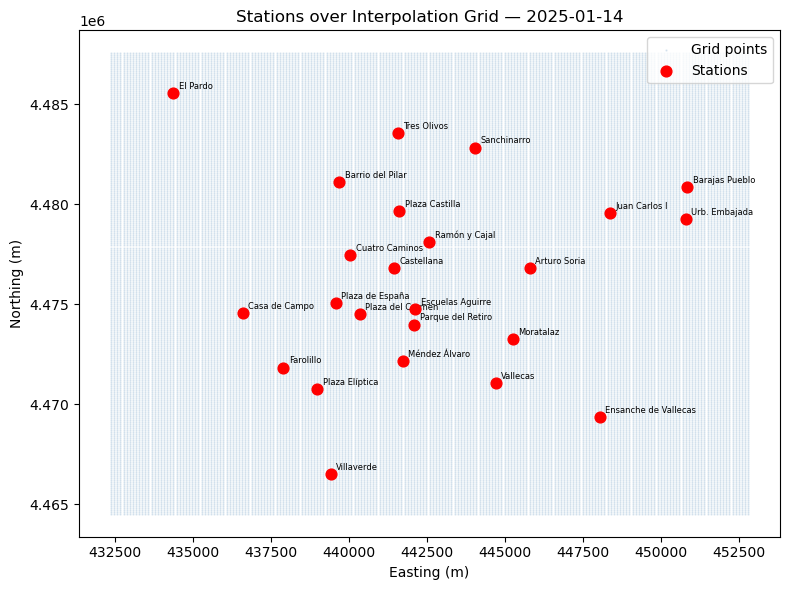

✅ Station grid saved


<Figure size 640x480 with 0 Axes>

In [35]:
# ── STEP 8b | Station Grid Preview ───────────────────────────────────────────
Xi_mesh, Yi_mesh = np.meshgrid(xi, yi)

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(Xi_mesh, Yi_mesh, s=0.5, alpha=0.15, color='steelblue', label='Grid points')
ax.scatter(x, y, color='red', s=60, zorder=5, label='Stations')

for _, row in one_day.iterrows():
    ax.annotate(
        row['STATION_NAME'],
        xy=(row.geometry.x, row.geometry.y),
        xytext=(4, 3), textcoords='offset points',
        fontsize=6, color='black'
    )

ax.set_title(f'Stations over Interpolation Grid — {TARGET_DATE}')
ax.set_xlabel('Easting (m)')
ax.set_ylabel('Northing (m)')
ax.legend()
plt.tight_layout()
plt.show()                                                         # ← VIEW
plt.savefig(f'outputs/station_grid_{TARGET_DATE}.png', dpi=150, bbox_inches='tight')
print("✅ Station grid saved")

In [36]:
# ── STEP 8c | NO₂ Values Table at Stations ────────────────────────────────────
print(f"\n{'='*60}")
print(f"  SENSOR NO₂ VALUES — ALL STATIONS — {TARGET_DATE}")
print(f"{'='*60}")
print(f"{'#':<4}{'Station':<30}{'Type':<12}{'NO₂ (µg/m³)':>12}")
print(f"{'-'*60}")

one_day_sorted = one_day.sort_values('NO2_daily_mean', ascending=False)
for i, (_, row) in enumerate(one_day_sorted.iterrows(), 1):
    print(f"{i:<4}{row['STATION_NAME']:<30}"
          f"{row['STATION_TYPE']:<12}"
          f"{row['NO2_daily_mean']:>12.2f}")

print(f"{'='*60}")
print(f"Mean : {one_day['NO2_daily_mean'].mean():.2f} µg/m³")
print(f"Max  : {one_day['NO2_daily_mean'].max():.2f} µg/m³")
print(f"Min  : {one_day['NO2_daily_mean'].min():.2f} µg/m³")


  SENSOR NO₂ VALUES — ALL STATIONS — 2025-01-14
#   Station                       Type         NO₂ (µg/m³)
------------------------------------------------------------
1   Barajas Pueblo                UF                 72.67
2   Urb. Embajada                 UF                 71.42
3   Villaverde                    UF                 69.08
4   Plaza Elíptica                UT                 66.83
5   Farolillo                     UF                 66.12
6   Ensanche de Vallecas          UF                 65.90
7   Plaza de España               UT                 63.00
8   Escuelas Aguirre              UT                 56.08
9   Barrio del Pilar              UT                 53.50
10  Vallecas                      UF                 52.52
11  Moratalaz                     UT                 50.58
12  Plaza del Carmen              UF                 49.76
13  Cuatro Caminos                UT                 48.46
14  Ramón y Cajal                 UT                 48.12
15  P

**STEP 9 | Save Kriging Results as GeoTIFF**

In [37]:
transform = from_origin(
    west=xi.min(), north=yi.max(),
    xsize=resolution, ysize=resolution
)

for fname, data in [
    (f'outputs/mapA_NO2_{TARGET_DATE}.tif',       z_grid),
    (f'outputs/mapB_variance_{TARGET_DATE}.tif',  var_grid)
]:
    with rasterio.open(
        fname, 'w', driver='GTiff',
        height=data.shape[0], width=data.shape[1],
        count=1, dtype='float32',
        crs='EPSG:25830', transform=transform
    ) as dst:
        dst.write(data.astype('float32'), 1)
    print(f"Saved: {fname}  ({os.path.getsize(fname):,} bytes)")


Saved: outputs/mapA_NO2_2025-01-14.tif  (189,936 bytes)
Saved: outputs/mapB_variance_2025-01-14.tif  (189,936 bytes)


**STEP 10 | Connect to GEE**

In [ ]:
# Google Earth Engine authentication
# First time only: run  earthengine authenticate  in your terminal.
# Then run this cell.
import ee

try:
    ee.Initialize(project='bi-capstone-494015')
    print('GEE connected')
except Exception:
    ee.Authenticate()
    ee.Initialize(project='bi-capstone-494015')
    print('GEE connected after auth')


**STEP 11 | Extract TROPOMI at Stations (Weekly Batches)**

In [ ]:
# Date range: 01/01/2025 → 28/02/2026
SAT_START = datetime.datetime(2025, 1,  1)
SAT_END   = datetime.datetime(2026, 2, 28)

In [ ]:
# Build GEE station FeatureCollection
station_meta = dffinal_merged[
    ['STATION_CODE', 'STATION_NAME', 'LATITUDE', 'LONGITUDE']
].drop_duplicates()

features = []
for _, row in station_meta.iterrows():
    pt   = ee.Geometry.Point([row['LONGITUDE'], row['LATITUDE']])
    feat = ee.Feature(pt, {
        'station_id'  : str(row['STATION_CODE']),
        'station_name': str(row['STATION_NAME'])
    })
    features.append(feat)

station_fc = ee.FeatureCollection(features)
print(f"Stations in GEE: {len(features)}")

In [ ]:
# Load full collection (no qa filter — mosaic handles orbit tiles)
full_collection = (
    ee.ImageCollection("COPERNICUS/S5P/OFFL/L3_NO2")
    .filterDate(SAT_START.strftime('%Y-%m-%d'),
                SAT_END.strftime('%Y-%m-%d'))
    .filterBounds(ee.Geometry.Rectangle([
        dffinal_merged['LONGITUDE'].min() - 0.1,
        dffinal_merged['LATITUDE'].min()  - 0.1,
        dffinal_merged['LONGITUDE'].max() + 0.1,
        dffinal_merged['LATITUDE'].max()  + 0.1
    ]))
    .select('tropospheric_NO2_column_number_density')
)

def sample_image(image):
    date_str = image.date().format('YYYY-MM-dd')
    sampled  = image.reduceRegions(
        collection=station_fc,
        reducer=ee.Reducer.mean(),
        scale=3500
    )
    return sampled.map(lambda f: f.set('date', date_str))

In [ ]:
# Weekly batch extraction
all_records = []
current = SAT_START

print("Extracting TROPOMI at stations — weekly batches ⏳")
while current < SAT_END:
    next_week = current + datetime.timedelta(days=7)
    chunk = full_collection.filterDate(
        current.strftime('%Y-%m-%d'),
        next_week.strftime('%Y-%m-%d')
    )
    chunk_samples = chunk.map(sample_image).flatten()
    try:
        records = chunk_samples.getInfo()['features']
        all_records.extend(records)
        print(f"  {current.date()} → {next_week.date()} : {len(records)} records")
    except Exception as e:
        print(f"  {current.date()} → {next_week.date()} :  {e}")
    current = next_week

print(f"\nTotal records: {len(all_records)}")


records = (# of satellite images in that period) × (# of stations)

1 station + 1 date + 1 NO₂ value Why images vary ,This is normal for Sentinel-5P (TROPOMI): Some days have: no valid data (clouds, filtering) missing coverage

In [ ]:
# Convert to DataFrame
rows = []
for f in all_records:
    props = f['properties']
    if f['geometry']:
        lon, lat = f['geometry']['coordinates']
    else:
        lon = lat = None
    rows.append({
        'station_id'  : props.get('station_id'),
        'station_name': props.get('station_name'),
        'date'        : props.get('date'),
        'NO2_sat'     : props.get('mean'),
        'lon'         : lon,
        'lat'         : lat
    })

df_sat = pd.DataFrame(rows)
df_sat['date'] = pd.to_datetime(df_sat['date'], errors='coerce')
df_sat = df_sat.dropna(subset=['NO2_sat', 'lat', 'lon'])
df_sat = df_sat.drop_duplicates(subset=['station_id', 'date'])
df_sat = df_sat.sort_values(['station_id', 'date']).reset_index(drop=True)

print(f"Satellite DataFrame: {df_sat.shape}")
print(f"Stations: {df_sat['station_id'].nunique()} | Dates: {df_sat['date'].nunique()}")
os.makedirs('outputs', exist_ok=True)
df_sat.to_csv('outputs/TROPOMI_NO2_2025_2026.csv', index=False)
print('Saved: outputs/TROPOMI_NO2_2025_2026.csv')

**STEP 12 | Get TROPOMI Spatial Grid for 2025-01-14**

In [ ]:
station_rect = ee.Geometry.Rectangle([-3.825, 40.297, -3.530, 40.568])

image_day = (
    ee.ImageCollection("COPERNICUS/S5P/OFFL/L3_NO2")
    .filterDate('2025-01-14', '2025-01-15')
    .filterBounds(station_rect)
    .select('tropospheric_NO2_column_number_density')
    .mosaic()
)
print(" TROPOMI mosaic built for 2025-01-14")

In [ ]:
# Sample a regular grid (~2km spacing)
lons = np.arange(-3.825, -3.530, 0.02)
lats = np.arange( 40.297,  40.568, 0.02)
LON_G, LAT_G = np.meshgrid(lons, lats)
points_flat  = list(zip(LON_G.flatten(), LAT_G.flatten()))

grid_features = [
    ee.Feature(ee.Geometry.Point([lon, lat]), {'pid': i})
    for i, (lon, lat) in enumerate(points_flat)
]
grid_fc = ee.FeatureCollection(grid_features)

sampled_grid = image_day.reduceRegions(
    collection=grid_fc, reducer=ee.Reducer.mean(), scale=3500
)

print(f"Sampling {len(points_flat)} grid points... ⏳")
grid_records = sampled_grid.getInfo()['features']

grid_rows = []
for feat in grid_records:
    coords = feat['geometry']['coordinates']
    val    = feat['properties'].get('mean')
    if val is not None:
        grid_rows.append({'lon': coords[0], 'lat': coords[1], 'NO2_grid': val})

df_grid = pd.DataFrame(grid_rows)
print(f"Valid grid points: {len(df_grid)}/{len(points_flat)}")


**STEP 13 | Get TROPOMI Values at Each Station for 2025-01-14**

In [ ]:
day_stations = dffinal_merged[
    dffinal_merged['date'].dt.strftime('%Y-%m-%d') == '2025-01-14'
].copy()

st_features = [
    ee.Feature(
        ee.Geometry.Point([row['LONGITUDE'], row['LATITUDE']]),
        {'station_id': str(row['STATION_CODE']),
         'station_name': str(row['STATION_NAME'])}
    )
    for _, row in day_stations.iterrows()
]

sampled_st = image_day.reduceRegions(
    collection=ee.FeatureCollection(st_features),
    reducer=ee.Reducer.mean(),
    scale=3500
)

st_rows = []
for feat in sampled_st.getInfo()['features']:
    props  = feat['properties']
    coords = feat['geometry']['coordinates']
    st_rows.append({
        'station_id'  : props.get('station_id'),
        'station_name': props.get('station_name'),
        'lon': coords[0], 'lat': coords[1],
        'NO2_sat': props.get('mean')
    })

df_st14 = pd.DataFrame(st_rows).dropna(subset=['NO2_sat'])
df_st14 = df_st14.sort_values('NO2_sat', ascending=False).reset_index(drop=True)

M_NO2, BL = 46.005, 1000
df_st14['NO2_ugm3'] = df_st14['NO2_sat'] * M_NO2 * 1e6 / BL

print(f"\n{'='*72}")
print(f"  TROPOMI NO₂ — ALL STATIONS — 2025-01-14")
print(f"{'='*72}")
print(f"{'#':<4}{'Station':<28}{'mol/m²':<18}{'µg/m³ proxy':>12}")
print(f"{'-'*72}")
for i, row in df_st14.iterrows():
    print(f"{i+1:<4}{row['station_name']:<28}"
          f"{row['NO2_sat']:<18.6e}{row['NO2_ugm3']:>12.2f}")
print(f"{'='*72}")
print(f"Mean: {df_st14['NO2_sat'].mean():.4e}  |  "
      f"Max: {df_st14['NO2_sat'].max():.4e}  |  "
      f"Min: {df_st14['NO2_sat'].min():.4e}")

df_st14.to_csv('outputs/no2_station_matrix_2025_01_14.csv', index=False)
print("Station matrix saved")


**STEP 14 | Final Side-by-Side Maps: Kriging vs Satellite**

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(18, 8))

In [ ]:
# ---------- MAP 1: Kriging (sensor interpolation) ----------
im1 = axes[0].contourf(xi, yi, z_grid, levels=25, cmap='YlOrRd')
axes[0].scatter(x, y, c=z, cmap='YlOrRd',
                edgecolors='black', linewidths=0.8, s=80, zorder=5)
cb1 = plt.colorbar(im1, ax=axes[0], shrink=0.85)
cb1.set_label('NO₂ (µg/m³)', fontsize=10)
axes[0].set_title('Sensor Kriging (Exponential)\n2025-01-14', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Easting (m)')
axes[0].set_ylabel('Northing (m)')

# Station values under kriging map
for _, row in one_day.iterrows():
    axes[0].annotate(
        f"{row['NO2_daily_mean']:.1f} µg/m³",
        xy=(row.geometry.x, row.geometry.y),
        xytext=(4, 3), textcoords='offset points',
        fontsize=6, color='black',
        bbox=dict(boxstyle='round,pad=0.15',
                  facecolor='white', alpha=0.6, edgecolor='none')
    )


In [ ]:
# ---------- MAP 2: TROPOMI satellite ----------
if len(df_grid) > 0:
    lon_lin = np.linspace(df_grid['lon'].min(), df_grid['lon'].max(), 400)
    lat_lin = np.linspace(df_grid['lat'].min(), df_grid['lat'].max(), 400)
    LON_I, LAT_I = np.meshgrid(lon_lin, lat_lin)

    Z_sat = griddata(
        points=df_grid[['lon', 'lat']].values,
        values=df_grid['NO2_grid'].values,
        xi=(LON_I, LAT_I),
        method='cubic'
    )

    im2 = axes[1].contourf(LON_I, LAT_I, Z_sat, levels=25,
                            cmap='RdYlGn_r', alpha=0.88)
    cb2 = plt.colorbar(im2, ax=axes[1], shrink=0.85)
    cb2.set_label('NO₂ column (mol/m²)', fontsize=10)

    axes[1].scatter(
        df_st14['lon'], df_st14['lat'],
        c=df_st14['NO2_sat'], cmap='RdYlGn_r',
        s=120, edgecolors='black', linewidths=1.2,
        zorder=5,
        vmin=df_grid['NO2_grid'].min(),
        vmax=df_grid['NO2_grid'].max()
    )
  # Station values under satellite map
    for _, row in df_st14.iterrows():
        axes[1].annotate(
            f"{row['NO2_sat']:.2e}",
            xy=(row['lon'], row['lat']),
            xytext=(4, 3), textcoords='offset points',
            fontsize=6, color='white', fontweight='bold',
            bbox=dict(boxstyle='round,pad=0.15',
                      facecolor='black', alpha=0.45, edgecolor='none')
        )

    axes[1].set_xlim(df_grid['lon'].min()-0.01, df_grid['lon'].max()+0.01)
    axes[1].set_ylim(df_grid['lat'].min()-0.01, df_grid['lat'].max()+0.01)
else:
    axes[1].text(0.5, 0.5, 'No satellite grid data\nfor this date',
                 ha='center', va='center', transform=axes[1].transAxes, fontsize=12)

axes[1].set_title('Sentinel-5P TROPOMI NO₂\n2025-01-14', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Longitude')
axes[1].set_ylabel('Latitude')

plt.suptitle('NO₂ Madrid — Sensor Kriging vs Satellite — 2025-01-14',
             fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('outputs/final_maps_2025_01_14.png', dpi=150, bbox_inches='tight')
plt.show()
print(" Final maps saved: final_maps_2025_01_14.png")

In [ ]:
# ── STEP 14b | Satellite Station Values Table ─────────────────────────────────
print(f"\n{'='*72}")
print(f"  TROPOMI NO₂ — ALL STATIONS — 2025-01-14")
print(f"{'='*72}")
print(f"{'#':<4}{'Station':<28}{'mol/m²':<18}{'µg/m³ proxy':>12}")
print(f"{'-'*72}")

for i, row in df_st14.iterrows():
    print(f"{i+1:<4}{row['station_name']:<28}"
          f"{row['NO2_sat']:<18.6e}"
          f"{row['NO2_ugm3']:>12.2f}")

print(f"{'='*72}")
print(f"Mean : {df_st14['NO2_sat'].mean():.4e} mol/m²"
      f"  →  {df_st14['NO2_ugm3'].mean():.2f} µg/m³")
print(f"Max  : {df_st14['NO2_sat'].max():.4e} mol/m²"
      f"  →  {df_st14['NO2_ugm3'].max():.2f} µg/m³")
print(f"Min  : {df_st14['NO2_sat'].min():.4e} mol/m²"
      f"  →  {df_st14['NO2_ugm3'].min():.2f} µg/m³")

In [ ]:
# ── DEBUG | Check exactly what's in df_grid ───────────────────────────────────
print("df_grid shape:", df_grid.shape)
print("df_grid columns:", df_grid.columns.tolist())
print("First few rows:")
print(df_grid.head())

In [ ]:
# ── FIX | Rebuild mosaic with wider bbox and check raw values ─────────────────
import ee
import numpy as np
import pandas as pd

if not ee.data._initialized:
    ee.Initialize(project='bi-capstone-494015')

# Use slightly wider bbox than stations
wider_rect = ee.Geometry.Rectangle([-4.0, 40.2, -3.4, 40.7])

image_day = (
    ee.ImageCollection("COPERNICUS/S5P/OFFL/L3_NO2")
    .filterDate('2025-01-14', '2025-01-15')
    .filterBounds(wider_rect)
    .select('tropospheric_NO2_column_number_density')
    .mosaic()
)

# ── First: check ONE point at Madrid center ───────────────────────────────────
val_center = image_day.reduceRegion(
    reducer  = ee.Reducer.mean(),
    geometry = ee.Geometry.Point([-3.68, 40.43]),
    scale    = 3500
).getInfo()
print("Value at Madrid center:", val_center)

# ── Check how many tiles exist for that day ───────────────────────────────────
n_tiles = (
    ee.ImageCollection("COPERNICUS/S5P/OFFL/L3_NO2")
    .filterDate('2025-01-14', '2025-01-15')
    .filterBounds(wider_rect)
    .size().getInfo()
)
print(f"TROPOMI tiles on 2025-01-14: {n_tiles}")

In [ ]:
# ── FIX |  sample grid with wider bbox ─────────────────────────
lons = np.arange(-4.00, -3.40, 0.02)
lats = np.arange(40.20,  40.70, 0.02)

LON_G, LAT_G = np.meshgrid(lons, lats)
points_flat  = list(zip(LON_G.flatten(), LAT_G.flatten()))
print(f"Grid points: {len(points_flat)}")

grid_features = [
    ee.Feature(ee.Geometry.Point([lon, lat]), {'pid': i})
    for i, (lon, lat) in enumerate(points_flat)
]
grid_fc = ee.FeatureCollection(grid_features)

sampled_grid = image_day.reduceRegions(
    collection = grid_fc,
    reducer    = ee.Reducer.mean(),
    scale      = 3500
)

print("Sampling... ⏳")
grid_records = sampled_grid.getInfo()['features']

grid_rows = []
for feat in grid_records:
    coords = feat['geometry']['coordinates']
    val    = feat['properties'].get('mean')
    if val is not None:
        grid_rows.append({
            'lon'     : coords[0],
            'lat'     : coords[1],
            'NO2_grid': val
        })

df_grid = pd.DataFrame(grid_rows)
print(f"Valid points: {len(df_grid)}/{len(points_flat)}")

if len(df_grid) > 0:
    print(df_grid.describe().round(8))
else:
    print(" Still 0 — 2025-01-14 has NO orbital coverage over Madrid")
    print("→ Switching to best available day from your overlap list...")

In [ ]:
# ── Define target day ─────────────────────────────────────────────────────────
GRID_DAY = '2025-01-14'
print("GRID_DAY set to:", GRID_DAY)

In [ ]:
# ── Get station values for 2025-01-14 from GEE ───────────────────────────────
day_st = dffinal_merged[
    dffinal_merged['date'].dt.strftime('%Y-%m-%d') == GRID_DAY
].copy()

st_features = [
    ee.Feature(
        ee.Geometry.Point([row['LONGITUDE'], row['LATITUDE']]),
        {'station_id'  : str(row['STATION_CODE']),
         'station_name': str(row['STATION_NAME'])}
    )
    for _, row in day_st.iterrows()
]

sampled_st = image_day.reduceRegions(
    collection = ee.FeatureCollection(st_features),
    reducer    = ee.Reducer.mean(),
    scale      = 3500
)

st_records = sampled_st.getInfo()['features']

st_rows = []
for feat in st_records:
    props  = feat['properties']
    coords = feat['geometry']['coordinates']
    st_rows.append({
        'station_name': props.get('station_name'),
        'lon'         : coords[0],
        'lat'         : coords[1],
        'NO2_sat'     : props.get('mean')
    })

df_st14 = pd.DataFrame(st_rows).dropna(subset=['NO2_sat'])
M_NO2, BL = 46.005, 1000
df_st14['NO2_ugm3'] = df_st14['NO2_sat'] * M_NO2 * 1e6 / BL
df_st14 = df_st14.sort_values('NO2_sat', ascending=False).reset_index(drop=True)

print(f"Stations with satellite data: {len(df_st14)}")
print(df_st14[['station_name', 'NO2_sat', 'NO2_ugm3']].to_string(index=False))

In [ ]:
# ── Interpolate satellite grid ────────────────────────────────────────────────
from scipy.interpolate import griddata
import numpy as np

lon_lin = np.linspace(df_grid['lon'].min(), df_grid['lon'].max(), 400)
lat_lin = np.linspace(df_grid['lat'].min(), df_grid['lat'].max(), 400)
LON_I, LAT_I = np.meshgrid(lon_lin, lat_lin)

Z_sat = griddata(
    points = df_grid[['lon', 'lat']].values,
    values = df_grid['NO2_grid'].values,
    xi     = (LON_I, LAT_I),
    method = 'cubic'
)

print("Z_sat shape:", Z_sat.shape)
print(f"Z_sat range: {np.nanmin(Z_sat):.4e} → {np.nanmax(Z_sat):.4e}")

In [ ]:
# ── Plot satellite map ────────────────────────────────────────────────────────
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(13, 10))

cf   = ax.contourf(LON_I, LAT_I, Z_sat, levels=25,
                   cmap='RdYlGn_r', alpha=0.88)
cbar = plt.colorbar(cf, ax=ax, shrink=0.8, pad=0.02)
cbar.set_label('TROPOMI NO₂ (mol/m²)', fontsize=11)

ax.scatter(
    df_st14['lon'], df_st14['lat'],
    c          = df_st14['NO2_sat'],
    cmap       = 'RdYlGn_r',
    s          = 150,
    edgecolors = 'black',
    linewidths = 1.5,
    zorder     = 5,
    vmin       = df_grid['NO2_grid'].min(),
    vmax       = df_grid['NO2_grid'].max()
)

for _, row in df_st14.iterrows():
    ax.annotate(
        f"{row['station_name']}\n"
        f"{row['NO2_sat']:.2e} mol/m²\n"
        f"{row['NO2_ugm3']:.1f} µg/m³",
        xy         = (row['lon'], row['lat']),
        xytext     = (6, 5),
        textcoords = 'offset points',
        fontsize   = 5.5,
        color      = 'white',
        fontweight = 'bold',
        bbox       = dict(boxstyle='round,pad=0.2',
                          facecolor='black', alpha=0.5, edgecolor='none')
    )

ax.set_xlim(df_grid['lon'].min()-0.01, df_grid['lon'].max()+0.01)
ax.set_ylim(df_grid['lat'].min()-0.01, df_grid['lat'].max()+0.01)
ax.set_title(
    f'Sentinel-5P TROPOMI NO₂ — Madrid — {GRID_DAY}\n'
    f'{len(df_grid)} grid points  |  {len(df_st14)} ground stations',
    fontsize=13, fontweight='bold', pad=12
)
ax.set_xlabel('Longitude', fontsize=11)
ax.set_ylabel('Latitude',  fontsize=11)

plt.tight_layout()
plt.show()
plt.savefig(f'outputs/satellite_map_{GRID_DAY}.png', dpi=150, bbox_inches='tight')
print(f"✅ Saved: satellite_map_{GRID_DAY}.png")

In [ ]:
# ── Station values table ──────────────────────────────────────────────────────
print(f"\n{'='*72}")
print(f"  TROPOMI NO₂ — ALL STATIONS — {GRID_DAY}")
print(f"{'='*72}")
print(f"{'#':<4}{'Station':<28}{'mol/m²':<20}{'µg/m³ proxy':>12}")
print(f"{'-'*72}")

for i, row in df_st14.iterrows():
    print(f"{i+1:<4}{row['station_name']:<28}"
          f"{row['NO2_sat']:<20.6e}"
          f"{row['NO2_ugm3']:>12.2f}")

print(f"{'='*72}")
print(f"Mean : {df_st14['NO2_sat'].mean():.4e}  →  {df_st14['NO2_ugm3'].mean():.2f} µg/m³")
print(f"Max  : {df_st14['NO2_sat'].max():.4e}  →  {df_st14['NO2_ugm3'].max():.2f} µg/m³")
print(f"Min  : {df_st14['NO2_sat'].min():.4e}  →  {df_st14['NO2_ugm3'].min():.2f} µg/m³")

---
# =========================================================
# PART 2 — DATA FUSION (Satellite + Sensor)
# Steps 15–23
# =========================================================
Combines Kriging sensor maps with TROPOMI satellite data:
satellite grid interpolation → unit conversion → spatial alignment
→ bias correction → uncertainty modeling → variance-weighted fusion.
The fused map `df_aligned` is the main input to the ML prediction model.

In [ ]:
# Check how much of Madrid your kriging grid covers
print("Kriging grid coverage:")
print(f"  Easting  : {xi.min():.0f} → {xi.max():.0f} m  ({(xi.max()-xi.min())/1000:.1f} km)")
print(f"  Northing : {yi.min():.0f} → {yi.max():.0f} m  ({(yi.max()-yi.min())/1000:.1f} km)")
print(f"  Pixels   : {len(xi)} × {len(yi)} = {len(xi)*len(yi):,}")

# Check satellite grid coverage
print("\nSatellite grid coverage:")
print(f"  Lon : {df_grid['lon'].min():.3f} → {df_grid['lon'].max():.3f}")
print(f"  Lat : {df_grid['lat'].min():.3f} → {df_grid['lat'].max():.3f}")
print(f"  Points : {len(df_grid)}")

 **STEP 15 | Satellite Grid Interpolation → Full Madrid Coverage**

In [ ]:
from scipy.interpolate import griddata
from pyproj import Transformer
import numpy as np
import pandas as pd

# ── 1. Interpolate satellite 210 points → full Madrid grid ──
# Use same lon/lat grid as satellite bbox
lon_lin = np.linspace(df_grid['lon'].min(), df_grid['lon'].max(), 300)
lat_lin = np.linspace(df_grid['lat'].min(), df_grid['lat'].max(), 300)
LON_I, LAT_I = np.meshgrid(lon_lin, lat_lin)

Z_sat_full = griddata(
    points=df_grid[['lon', 'lat']].values,
    values=df_grid['NO2_grid'].values,
    xi=(LON_I, LAT_I),
    method='cubic'
)

# ── 2. Convert to DataFrame ──────────────────────────────────
df_satellite_full = pd.DataFrame({
    'lon'      : LON_I.flatten(),
    'lat'      : LAT_I.flatten(),
    'NO2_satellite': Z_sat_full.flatten()
})

# Drop NaN pixels (edges from cubic interpolation)
df_satellite_full = df_satellite_full.dropna(subset=['NO2_satellite']).reset_index(drop=True)
df_satellite_full['date'] = TARGET_DATE

print(f"Total satellite pixels: {len(df_satellite_full):,}")
print(f"NO2 range: {df_satellite_full['NO2_satellite'].min():.4e} → "
      f"{df_satellite_full['NO2_satellite'].max():.4e} mol/m²")
print(df_satellite_full.head())

# ── 3. Save ──────────────────────────────────────────────────
df_satellite_full.to_csv(f'outputs/NO2_satellite_full_madrid_{TARGET_DATE}.csv', index=False)
print(f"✅ Saved → NO2_satellite_full_madrid_{TARGET_DATE}.csv")

**STEP 16 | Kriging Grid → Full Madrid Coverage DataFrame**

In [ ]:
# Convert kriging grid to a full DataFrame of NO2 values over Madrid
Xi_mesh, Yi_mesh = np.meshgrid(xi, yi)

df_kriging_full = pd.DataFrame({
    'easting' : Xi_mesh.flatten(),
    'northing': Yi_mesh.flatten(),
    'NO2_kriging' : np.array(z_grid).flatten(),
    'NO2_variance': np.array(var_grid).flatten()
})

# Convert UTM back to WGS84 (lon/lat) to match satellite coordinates
from pyproj import Transformer
transformer_back = Transformer.from_crs("EPSG:25830", "EPSG:4326", always_xy=True)
df_kriging_full['lon'], df_kriging_full['lat'] = transformer_back.transform(
    df_kriging_full['easting'].values,
    df_kriging_full['northing'].values
)

# Keep only pixels inside Madrid bbox
df_kriging_full = df_kriging_full[
    (df_kriging_full['lon'] >= -3.825) & (df_kriging_full['lon'] <= -3.530) &
    (df_kriging_full['lat'] >=  40.297) & (df_kriging_full['lat'] <=  40.568)
].reset_index(drop=True)

df_kriging_full['date'] = TARGET_DATE

print(f"Total pixels with NO2 values: {len(df_kriging_full):,}")
print(f"NO2 range: {df_kriging_full['NO2_kriging'].min():.2f} → {df_kriging_full['NO2_kriging'].max():.2f} µg/m³")
print(df_kriging_full.head())

# Save
df_kriging_full.to_csv(f'outputs/NO2_full_madrid_{TARGET_DATE}.csv', index=False)
print(f"✅ Saved → NO2_full_madrid_{TARGET_DATE}.csv")

**STEP 17 | Satellite Unit Conversion — mol/m² → µg/m³**

In [ ]:
BL    = 200     # meters — winter boundary layer height over Madrid
M_NO2 = 46.005  # g/mol — molecular weight of NO2
df_satellite_full['NO2_sat_ugm3'] = df_satellite_full['NO2_satellite'] * M_NO2 * 1e6 / BL
df_st14['NO2_ugm3']               = df_st14['NO2_sat']                 * M_NO2 * 1e6 / BL

print(f"Boundary layer used : {BL} m")
print(f"{'='*55}")
print(f"  AFTER CONVERSION")
print(f"{'='*55}")
print(f"  Satellite full grid:")
print(f"    min : {df_satellite_full['NO2_sat_ugm3'].min():.2f} µg/m³")
print(f"    max : {df_satellite_full['NO2_sat_ugm3'].max():.2f} µg/m³")
print(f"    mean: {df_satellite_full['NO2_sat_ugm3'].mean():.2f} µg/m³")
print(f"{'='*55}")
print(f"  Station-level (df_st14):")
print(f"    min : {df_st14['NO2_ugm3'].min():.2f} µg/m³")
print(f"    max : {df_st14['NO2_ugm3'].max():.2f} µg/m³")
print(f"    mean: {df_st14['NO2_ugm3'].mean():.2f} µg/m³")
print(f"{'='*55}")
print(f"\n  Ground sensor reference (2025-01-14):")
print(f"    min : 22.04 µg/m³")
print(f"    max : 72.67 µg/m³")
print(f"    mean: 50.89 µg/m³")

**STEP 18 | Side-by-Side Comparison — Sensor Kriging vs Satellite TROPOMI**

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
fig.suptitle(f'NO₂ over Madrid — Ground Sensors vs Satellite — {TARGET_DATE}',
             fontsize=14, fontweight='bold')

# Shared color scale across both maps
vmin = min(df_kriging_full['NO2_kriging'].min(), df_satellite_full['NO2_sat_ugm3'].min())
vmax = max(df_kriging_full['NO2_kriging'].max(), df_satellite_full['NO2_sat_ugm3'].max())

# ── Map 1: Sensor Kriging ────────────────────────────────────
im1 = axes[0].contourf(xi, yi, z_grid, levels=25, cmap='YlOrRd',
                        vmin=vmin, vmax=vmax)
axes[0].scatter(x, y, c=z, cmap='YlOrRd', edgecolors='black',
                linewidths=0.8, s=80, zorder=5, vmin=vmin, vmax=vmax)
cb1 = plt.colorbar(im1, ax=axes[0], shrink=0.85)
cb1.set_label('NO₂ (µg/m³)', fontsize=10)
axes[0].set_title('Ground Sensors — Kriging Interpolation', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Easting (m)')
axes[0].set_ylabel('Northing (m)')

# Annotate station values
for _, row in one_day.iterrows():
    axes[0].annotate(
        f"{row['NO2_daily_mean']:.1f}",
        xy=(row.geometry.x, row.geometry.y),
        xytext=(4, 3), textcoords='offset points',
        fontsize=6, color='black',
        bbox=dict(boxstyle='round,pad=0.15',
                  facecolor='white', alpha=0.6, edgecolor='none')
    )

# ── Map 2: Satellite TROPOMI ─────────────────────────────────
# Reshape satellite data back to 2D grid for contourf
lon_lin = np.linspace(df_grid['lon'].min(), df_grid['lon'].max(), 300)
lat_lin = np.linspace(df_grid['lat'].min(), df_grid['lat'].max(), 300)
LON_I, LAT_I = np.meshgrid(lon_lin, lat_lin)
Z_sat_2d = df_satellite_full['NO2_sat_ugm3'].values.reshape(LON_I.shape)

im2 = axes[1].contourf(LON_I, LAT_I, Z_sat_2d, levels=25, cmap='YlOrRd',
                        vmin=vmin, vmax=vmax)
axes[1].scatter(df_st14['lon'], df_st14['lat'],
                c=df_st14['NO2_ugm3'], cmap='YlOrRd',
                edgecolors='black', linewidths=0.8, s=80, zorder=5,
                vmin=vmin, vmax=vmax)
cb2 = plt.colorbar(im2, ax=axes[1], shrink=0.85)
cb2.set_label('NO₂ (µg/m³)', fontsize=10)
axes[1].set_title('Satellite TROPOMI — Interpolated', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Longitude')
axes[1].set_ylabel('Latitude')

# Annotate satellite station values
for _, row in df_st14.iterrows():
    axes[1].annotate(
        f"{row['NO2_ugm3']:.1f}",
        xy=(row['lon'], row['lat']),
        xytext=(4, 3), textcoords='offset points',
        fontsize=6, color='black',
        bbox=dict(boxstyle='round,pad=0.15',
                  facecolor='white', alpha=0.6, edgecolor='none')
    )

axes[1].set_xlim(df_grid['lon'].min()-0.01, df_grid['lon'].max()+0.01)
axes[1].set_ylim(df_grid['lat'].min()-0.01, df_grid['lat'].max()+0.01)

plt.tight_layout()
plt.savefig(f'outputs/comparison_maps_{TARGET_DATE}.png', dpi=150, bbox_inches='tight')
plt.show()
print(f"✅ Saved → comparison_maps_{TARGET_DATE}.png")

 **WHY THE VALUES ARE NOT THESAME**

Ground sensors measure surface only, satellite measures the entire atmosphere column

TROPOMI pixel = 3.5km, sensor = one point → spatial averaging difference

TROPOMI captures one moment (~13:30), sensors average over 24 hours

BL=200m is a fixed assumption, real boundary layer height varies across Madrid

Clouds and local emissions too small for satellite to detect at its resolution

**STEP 19 | Spatial Alignment — KD-Tree Nearest Neighbor**

In [ ]:
from scipy.spatial import cKDTree
# ── 1. Build KD-Tree from satellite grid points ──────────────
sat_coords = df_satellite_full[['lon', 'lat']].values
tree = cKDTree(sat_coords)

# ── 2. Query nearest satellite pixel for each kriging pixel ──
krig_coords = df_kriging_full[['lon', 'lat']].values
distances, indices = tree.query(krig_coords, k=1)

# ── 3. Assign matched satellite values to kriging pixels ─────
df_aligned = df_kriging_full.copy()
df_aligned['NO2_sat_ugm3']    = df_satellite_full.iloc[indices]['NO2_sat_ugm3'].values
df_aligned['NO2_satellite']   = df_satellite_full.iloc[indices]['NO2_satellite'].values
df_aligned['dist_to_sat_px']  = distances  # distance in degrees to nearest sat pixel

# ── 4. Validation ────────────────────────────────────────────
print(f"{'='*55}")
print(f"  STEP 19 — Spatial Alignment Results")
print(f"{'='*55}")
print(f"  Total aligned pixels  : {len(df_aligned):,}")
print(f"  Max match distance    : {distances.max():.4f}°")
print(f"  Mean match distance   : {distances.mean():.4f}°")
print(f"{'='*55}")
print(f"  NO2 Kriging  (µg/m³)  : {df_aligned['NO2_kriging'].min():.2f} → {df_aligned['NO2_kriging'].max():.2f}")
print(f"  NO2 Satellite(µg/m³)  : {df_aligned['NO2_sat_ugm3'].min():.2f} → {df_aligned['NO2_sat_ugm3'].max():.2f}")
print(f"{'='*55}")
print(df_aligned[['lon', 'lat', 'NO2_kriging', 'NO2_sat_ugm3',
                   'NO2_variance', 'dist_to_sat_px']].head())

# ── 5. Save ──────────────────────────────────────────────────
df_aligned.to_csv(f'outputs/NO2_aligned_{TARGET_DATE}.csv', index=False)
print(f"\n✅ Saved → NO2_aligned_{TARGET_DATE}.csv")

 **STEP 20 | Regression Calibration**

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

# ── 1. Build calibration dataset from 24 stations ───────────
# Match df_st14 (satellite at stations) with one_day (sensor at stations)
df_calib = pd.merge(
    one_day[['STATION_NAME', 'NO2_daily_mean']].reset_index(drop=True),
    df_st14[['station_name', 'NO2_ugm3']].reset_index(drop=True),
    left_on='STATION_NAME', right_on='station_name',
    how='inner'
).dropna()

print(f"Calibration points : {len(df_calib)} stations")
print(df_calib[['STATION_NAME', 'NO2_daily_mean', 'NO2_ugm3']].to_string(index=False))

# ── 2. Train Linear Regression ───────────────────────────────
X = df_calib['NO2_ugm3'].values.reshape(-1, 1)      # satellite
y = df_calib['NO2_daily_mean'].values                # sensor (ground truth)

reg = LinearRegression()
reg.fit(X, y)

slope     = reg.coef_[0]
intercept = reg.intercept_
r2        = r2_score(y, reg.predict(X))
rmse      = np.sqrt(mean_squared_error(y, reg.predict(X)))

print(f"\n{'='*55}")
print(f"  Regression Results")
print(f"{'='*55}")
print(f"  Slope     : {slope:.4f}")
print(f"  Intercept : {intercept:.4f}")
print(f"  R²        : {r2:.4f}")
print(f"  RMSE      : {rmse:.4f} µg/m³")
print(f"{'='*55}")

# ── 3. Apply calibration to all 74,816 pixels ───────────────
df_aligned['NO2_sat_calibrated'] = reg.predict(
    df_aligned['NO2_sat_ugm3'].values.reshape(-1, 1)
)

print(f"\n  NO2 Satellite raw       : {df_aligned['NO2_sat_ugm3'].min():.2f} → {df_aligned['NO2_sat_ugm3'].max():.2f} µg/m³")
print(f"  NO2 Satellite calibrated: {df_aligned['NO2_sat_calibrated'].min():.2f} → {df_aligned['NO2_sat_calibrated'].max():.2f} µg/m³")
print(f"  NO2 Kriging (reference) : {df_aligned['NO2_kriging'].min():.2f} → {df_aligned['NO2_kriging'].max():.2f} µg/m³")

# ── 4. Scatter plot — before vs after calibration ───────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Regression Calibration — Satellite vs Sensor', fontsize=13, fontweight='bold')

# Before calibration
axes[0].scatter(df_calib['NO2_ugm3'], df_calib['NO2_daily_mean'],
                color='steelblue', edgecolors='black', s=80, zorder=5)
x_line = np.linspace(df_calib['NO2_ugm3'].min(), df_calib['NO2_ugm3'].max(), 100)
axes[0].plot(x_line, reg.predict(x_line.reshape(-1,1)), 'r--', linewidth=2)
axes[0].plot(x_line, x_line, 'k:', linewidth=1, label='1:1 line')
axes[0].set_xlabel('Satellite NO₂ (µg/m³)')
axes[0].set_ylabel('Sensor NO₂ (µg/m³)')
axes[0].set_title(f'Before Calibration\nR²={r2:.3f}  RMSE={rmse:.2f} µg/m³')
axes[0].legend()

# After calibration
y_pred = reg.predict(X)
axes[1].scatter(y_pred, y, color='seagreen', edgecolors='black', s=80, zorder=5)
axes[1].plot([y.min(), y.max()], [y.min(), y.max()], 'k:', linewidth=1, label='1:1 line')
axes[1].set_xlabel('Calibrated Satellite NO₂ (µg/m³)')
axes[1].set_ylabel('Sensor NO₂ (µg/m³)')
axes[1].set_title(f'After Calibration\nR²={r2:.3f}  RMSE={rmse:.2f} µg/m³')
axes[1].legend()

plt.tight_layout()
plt.savefig(f'outputs/regression_calibration_{TARGET_DATE}.png', dpi=150, bbox_inches='tight')
plt.show()
print(f"✅ Saved → regression_calibration_{TARGET_DATE}.png")

The R²=0.067 is very low — meaning the linear regression found almost no correlation between satellite and sensor at the 24 stations.

Since only 24 points with low spatial variability at satellite resolution cannot train a reliable regression, we will switch to a robust bias correction

**STEP 20 REVISED | Bias Correction**

In [ ]:
# 1. Compute mean bias between satellite and sensor at 24 stations
df_calib['bias'] = df_calib['NO2_daily_mean'] - df_calib['NO2_ugm3']

mean_bias = df_calib['bias'].mean()
std_bias  = df_calib['bias'].std()

print(f"{'='*55}")
print(f"  Bias Analysis at 24 Stations")
print(f"{'='*55}")
print(f"  Mean bias (sensor - satellite) : {mean_bias:.2f} µg/m³")
print(f"  Std  bias                      : {std_bias:.2f} µg/m³")
print(f"  Interpretation: sensor is on average {mean_bias:.2f} µg/m³")
print(f"  {'higher' if mean_bias > 0 else 'lower'} than satellite")
print(f"{'='*55}")

# Per station bias
print(f"\n{'Station':<28} {'Sensor':>10} {'Satellite':>10} {'Bias':>10}")
print("-"*60)
for _, row in df_calib.iterrows():
    print(f"{row['STATION_NAME']:<28} {row['NO2_daily_mean']:>10.2f} "
          f"{row['NO2_ugm3']:>10.2f} {row['bias']:>10.2f}")

# 2. Apply bias correction to all pixels
df_aligned['NO2_sat_calibrated'] = df_aligned['NO2_sat_ugm3'] + mean_bias

print(f"\n  NO2 Satellite raw       : {df_aligned['NO2_sat_ugm3'].min():.2f} → {df_aligned['NO2_sat_ugm3'].max():.2f} µg/m³")
print(f"  NO2 Satellite calibrated: {df_aligned['NO2_sat_calibrated'].min():.2f} → {df_aligned['NO2_sat_calibrated'].max():.2f} µg/m³")
print(f"  NO2 Kriging (reference) : {df_aligned['NO2_kriging'].min():.2f} → {df_aligned['NO2_kriging'].max():.2f} µg/m³")

# 3. Visualize bias distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Bias Correction — Satellite vs Sensor', fontsize=13, fontweight='bold')

# Bias per station
axes[0].bar(range(len(df_calib)), df_calib['bias'].values,
            color=['seagreen' if b > 0 else 'tomato' for b in df_calib['bias']],
            edgecolor='black')
axes[0].axhline(mean_bias, color='navy', linestyle='--', linewidth=2,
                label=f'Mean bias = {mean_bias:.2f} µg/m³')
axes[0].set_xticks(range(len(df_calib)))
axes[0].set_xticklabels(df_calib['STATION_NAME'], rotation=90, fontsize=7)
axes[0].set_ylabel('Bias (µg/m³)')
axes[0].set_title('Per-Station Bias (Sensor − Satellite)')
axes[0].legend()

# Before vs after correction scatter
axes[1].scatter(df_calib['NO2_ugm3'], df_calib['NO2_daily_mean'],
                color='steelblue', label='Raw satellite', s=80, edgecolors='black')
axes[1].scatter(df_calib['NO2_ugm3'] + mean_bias, df_calib['NO2_daily_mean'],
                color='seagreen', label='Bias corrected', s=80, edgecolors='black')
ref_line = np.linspace(20, 85, 100)
axes[1].plot(ref_line, ref_line, 'k:', linewidth=1, label='1:1 line')
axes[1].set_xlabel('Satellite NO₂ (µg/m³)')
axes[1].set_ylabel('Sensor NO₂ (µg/m³)')
axes[1].set_title('Scatter — Before vs After Bias Correction')
axes[1].legend()

plt.tight_layout()
plt.savefig(f'outputs/bias_correction_{TARGET_DATE}.png', dpi=150, bbox_inches='tight')
plt.show()
print(f"✅ Saved → bias_correction_{TARGET_DATE}.png")

**STEP 21 | Uncertainty Modeling**

In [ ]:
# ── Recompute correct station coordinates ────────────────────
x_stations = one_day.geometry.x.values   # easting  (UTM metres)
y_stations = one_day.geometry.y.values   # northing (UTM metres)

print("x_stations range:", x_stations.min(), "→", x_stations.max())
print("y_stations range:", y_stations.min(), "→", y_stations.max())

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
fig.suptitle(f'Uncertainty Modeling — {TARGET_DATE}', fontsize=13, fontweight='bold')

im1 = axes[0].contourf(xi, yi, var_norm_2d, levels=20, cmap='Blues')
axes[0].scatter(x_stations, y_stations, c='red', s=40, zorder=5, label='Stations')
plt.colorbar(im1, ax=axes[0], label='Normalized Variance')
axes[0].set_title('Kriging Uncertainty (normalized)')
axes[0].set_xlabel('Easting (m)')
axes[0].set_ylabel('Northing (m)')
axes[0].legend()

im2 = axes[1].contourf(xi, yi, ws_2d, levels=20, cmap='Greens')
axes[1].scatter(x_stations, y_stations, c='red', s=40, zorder=5, label='Stations')
plt.colorbar(im2, ax=axes[1], label='Sensor Weight')
axes[1].set_title('Sensor Weight (w_sensor)\nHigh near stations')
axes[1].set_xlabel('Easting (m)')
axes[1].legend()

im3 = axes[2].contourf(xi, yi, wsat_2d, levels=20, cmap='Oranges')
axes[2].scatter(x_stations, y_stations, c='red', s=40, zorder=5, label='Stations')
plt.colorbar(im3, ax=axes[2], label='Satellite Weight')
axes[2].set_title('Satellite Weight (w_satellite)\nHigh far from stations')
axes[2].set_xlabel('Easting (m)')
axes[2].legend()

plt.tight_layout()
plt.savefig(f'outputs/uncertainty_weights_{TARGET_DATE}.png', dpi=150, bbox_inches='tight')
plt.show()
print(f"✅ Saved → uncertainty_weights_{TARGET_DATE}.png")

**STEP 22 | Variance-Weighted Fusion**

In [ ]:
from scipy.interpolate import griddata
from pyproj import Transformer

# ── 1. Fuse sensor + calibrated satellite ───────────────────
df_aligned['NO2_fused'] = (
    df_aligned['w_sensor']    * df_aligned['NO2_kriging'] +
    df_aligned['w_satellite'] * df_aligned['NO2_sat_calibrated']
)

# ── 2. Clip to physically valid range ───────────────────────
NO2_min_valid = df_aligned['NO2_kriging'].min()
NO2_max_valid = df_aligned['NO2_kriging'].max()

df_aligned['NO2_fused'] = df_aligned['NO2_fused'].clip(
    lower=NO2_min_valid,
    upper=NO2_max_valid
)

# ── 3. Print results ─────────────────────────────────────────
print(f"{'='*55}")
print(f"  STEP 22 — Fusion Results")
print(f"{'='*55}")
print(f"  NO2 Kriging          : {df_aligned['NO2_kriging'].min():.2f} → {df_aligned['NO2_kriging'].max():.2f} µg/m³")
print(f"  NO2 Sat calibrated   : {df_aligned['NO2_sat_calibrated'].min():.2f} → {df_aligned['NO2_sat_calibrated'].max():.2f} µg/m³")
print(f"  NO2 Fused            : {df_aligned['NO2_fused'].min():.2f} → {df_aligned['NO2_fused'].max():.2f} µg/m³")
print(f"  Mean NO2 Kriging     : {df_aligned['NO2_kriging'].mean():.2f} µg/m³")
print(f"  Mean NO2 Sat         : {df_aligned['NO2_sat_calibrated'].mean():.2f} µg/m³")
print(f"  Mean NO2 Fused       : {df_aligned['NO2_fused'].mean():.2f} µg/m³")
print(f"  Pixels clipped       : {(df_aligned['NO2_fused'] == NO2_min_valid).sum()} low  |  "
      f"{(df_aligned['NO2_fused'] == NO2_max_valid).sum()} high")
print(f"{'='*55}")

# ── 4. Reproject mesh for griddata ──────────────────────────
Xi_mesh, Yi_mesh = np.meshgrid(xi, yi)
transformer_back  = Transformer.from_crs("EPSG:25830", "EPSG:4326", always_xy=True)
lon_mesh, lat_mesh = transformer_back.transform(Xi_mesh.flatten(), Yi_mesh.flatten())

coords = df_aligned[['lon', 'lat']].values

# ── 5. Regrid all 3 surfaces for plotting ───────────────────
krig_2d = griddata(coords, df_aligned['NO2_kriging'].values,
                   (lon_mesh.reshape(Xi_mesh.shape),
                    lat_mesh.reshape(Xi_mesh.shape)), method='linear')

sat_2d  = griddata(coords, df_aligned['NO2_sat_calibrated'].values,
                   (lon_mesh.reshape(Xi_mesh.shape),
                    lat_mesh.reshape(Xi_mesh.shape)), method='linear')

fused_2d = griddata(coords, df_aligned['NO2_fused'].values,
                    (lon_mesh.reshape(Xi_mesh.shape),
                     lat_mesh.reshape(Xi_mesh.shape)), method='linear')

# ── 6. Plot — 3 maps side by side ───────────────────────────
vmin = NO2_min_valid
vmax = NO2_max_valid

fig, axes = plt.subplots(1, 3, figsize=(22, 7))
fig.suptitle(f'NO₂ Fusion Results — {TARGET_DATE}', fontsize=14, fontweight='bold')

# Map 1 — Sensor Kriging
im1 = axes[0].contourf(xi, yi, krig_2d, levels=25, cmap='YlOrRd', vmin=vmin, vmax=vmax)
axes[0].scatter(x_stations, y_stations, c='black', s=40, zorder=5, label='Stations')
plt.colorbar(im1, ax=axes[0], label='NO₂ (µg/m³)')
axes[0].set_title('Sensor Kriging\n(ground truth)', fontsize=11, fontweight='bold')
axes[0].set_xlabel('Easting (m)')
axes[0].set_ylabel('Northing (m)')
axes[0].legend()

# Map 2 — Calibrated Satellite
im2 = axes[1].contourf(xi, yi, sat_2d, levels=25, cmap='YlOrRd', vmin=vmin, vmax=vmax)
axes[1].scatter(x_stations, y_stations, c='black', s=40, zorder=5, label='Stations')
plt.colorbar(im2, ax=axes[1], label='NO₂ (µg/m³)')
axes[1].set_title('Calibrated Satellite\n(bias corrected)', fontsize=11, fontweight='bold')
axes[1].set_xlabel('Easting (m)')
axes[1].legend()

# Map 3 — Fused
im3 = axes[2].contourf(xi, yi, fused_2d, levels=25, cmap='YlOrRd', vmin=vmin, vmax=vmax)
axes[2].scatter(x_stations, y_stations, c='black', s=40, zorder=5, label='Stations')
plt.colorbar(im3, ax=axes[2], label='NO₂ (µg/m³)')
axes[2].set_title('Fused NO₂\n(sensor + satellite)', fontsize=11, fontweight='bold')
axes[2].set_xlabel('Easting (m)')
axes[2].legend()

plt.tight_layout()
plt.savefig(f'outputs/fusion_result_{TARGET_DATE}.png', dpi=150, bbox_inches='tight')
plt.show()
print(f"✅ Saved → fusion_result_{TARGET_DATE}.png")

**STEP 23 | Save Fused Results**

In [ ]:
import rasterio
from rasterio.transform import from_origin
import os


# ── 1. Save fused DataFrame as CSV ──────────────────────────
df_aligned.to_csv(f'outputs/NO2_fused_{TARGET_DATE}.csv', index=False)
print(f"✅ CSV saved → NO2_fused_{TARGET_DATE}.csv  ({len(df_aligned):,} pixels)")

# ── 2. Save fused surface as GeoTIFF ────────────────────────
transform = from_origin(
    west=xi.min(),
    north=yi.max() + 100,
    xsize=100,
    ysize=100
)

for fname, data_2d in [
    (f'outputs/NO2_fused_{TARGET_DATE}.tif',      fused_2d),
    (f'outputs/NO2_kriging_{TARGET_DATE}.tif',    krig_2d),
    (f'outputs/NO2_satellite_{TARGET_DATE}.tif',  sat_2d),
]:
    data_np = np.array(data_2d, dtype='float32')
    with rasterio.open(
        fname, 'w',
        driver='GTiff',
        height=data_np.shape[0],
        width=data_np.shape[1],
        count=1,
        dtype='float32',
        crs='EPSG:25830',
        transform=transform
    ) as dst:
        dst.write(data_np, 1)
    print(f"✅ GeoTIFF saved → {os.path.basename(fname)}  ({os.path.getsize(fname):,} bytes)")

# ── 3. Verify all saved files ────────────────────────────────
print(f"\n{'='*55}")
print(f"  STEP 23 — Saved Files Summary")
print(f"{'='*55}")
for fname in [
    f'outputs/NO2_fused_{TARGET_DATE}.csv',
    f'outputs/NO2_fused_{TARGET_DATE}.tif',
    f'outputs/NO2_kriging_{TARGET_DATE}.tif',
    f'outputs/NO2_satellite_{TARGET_DATE}.tif',
]:
    size = os.path.getsize(fname)
    print(f"  {os.path.basename(fname):<45} {size:>10,} bytes")

print(f"\n  Fused DataFrame shape : {df_aligned.shape}")
print(f"  Columns saved         : {df_aligned.columns.tolist()}")
print(f"{'='*55}")
print(f"\n✅ All results saved successfully!")

In [ ]:

# Download all fusion files at once
# files.download(f'outputs/NO2_fused_{TARGET_DATE}.csv')
# files.download(f'outputs/NO2_fused_{TARGET_DATE}.tif')
# files.download(f'outputs/NO2_kriging_{TARGET_DATE}.tif')
# files.download(f'outputs/NO2_satellite_{TARGET_DATE}.tif')
# files.download(f'outputs/fusion_result_{TARGET_DATE}.png')
# files.download(f'outputs/uncertainty_weights_{TARGET_DATE}.png')
# files.download(f'outputs/regression_calibration_{TARGET_DATE}.png')

---
# =========================================================
# PART 3 — MACHINE LEARNING PREDICTION
# Steps 24–32
# =========================================================
Uses `dffinal_merged` (sensor data) and `df_aligned` (fused map) from Parts 1–2.
Builds CNN-LSTM model for multi-horizon NO₂ forecasting (t+1, t+7, t+14),
with MC-Dropout uncertainty, prediction maps, and risk classification.

### Bridge: Fused Map → ML Dataset
If you ran Part 2 (GEE + fusion), `df_aligned` contains the fused NO₂ grid.
The ML model uses `dffinal_merged` for station-level time series (always available)
and optionally enriches features with the fused spatial map from `df_aligned`.

In [ ]:
# ── Check what fusion data is available ─────────────────────────────────────
import os
os.makedirs('outputs', exist_ok=True)

try:
    _ = df_aligned
    HAS_FUSION = True
    print('✅ df_aligned found — fused satellite+sensor map available')
    print(f'   Shape: {df_aligned.shape}')
    print(f'   Columns: {df_aligned.columns.tolist()}')
except NameError:
    HAS_FUSION = False
    print('⚠️  df_aligned not found — GEE steps were skipped')
    print('   ML model will use sensor + weather data only (still valid)')


In [ ]:
# ── Optional: enrich station features with fused map ────────────────────────
# If df_aligned exists, add the mean fused NO₂ value per station per day
# as an additional input channel to the sequence model.

if HAS_FUSION:
    from scipy.spatial import cKDTree
    from pyproj import Transformer

    # Get station UTM coords
    transformer = Transformer.from_crs('EPSG:4326', 'EPSG:25830', always_xy=True)
    sta_meta = dffinal_merged[['STATION_CODE','LONGITUDE','LATITUDE']].drop_duplicates()
    sta_meta['easting'], sta_meta['northing'] = transformer.transform(
        sta_meta['LONGITUDE'].values, sta_meta['LATITUDE'].values
    )

    # Nearest fused pixel per station
    tree = cKDTree(df_aligned[['lon','lat']].values)
    _, idx = tree.query(sta_meta[['LONGITUDE','LATITUDE']].values, k=1)
    sta_meta['NO2_fused_ref'] = df_aligned.iloc[idx]['NO2_fused'].values

    dffinal_merged = dffinal_merged.merge(
        sta_meta[['STATION_CODE','NO2_fused_ref']], on='STATION_CODE', how='left'
    )
    print('✅ Fused NO₂ reference added to dffinal_merged')
    print(dffinal_merged[['STATION_NAME','NO2_fused_ref']].drop_duplicates().to_string(index=False))
else:
    print('Using sensor+weather features only (no fusion enrichment)')


# STEP 24 —  SENSOR DATASET


I created here the machine learning dataset as a table of:
9,892 rows = one station on one day
For 24 stations over ~423 days.
Each row says:
“At this station, on this date, NO₂ was this value.”

In [38]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
from sklearn.preprocessing import LabelEncoder, MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

os.makedirs('outputs', exist_ok=True)

df_sensor = dffinal_merged.copy()
df_sensor = df_sensor.rename(columns={'NO2_daily_mean': 'target_NO2'})
df_sensor = df_sensor.dropna(subset=['target_NO2'])

df_sensor['year']       = df_sensor['date'].dt.year
df_sensor['month']      = df_sensor['date'].dt.month
df_sensor['day']        = df_sensor['date'].dt.day
df_sensor['weekday']    = df_sensor['date'].dt.weekday
df_sensor['day_of_year']= df_sensor['date'].dt.dayofyear

le = LabelEncoder()
df_sensor['STATION_TYPE_ENC'] = le.fit_transform(df_sensor['STATION_TYPE'].astype(str))

print('df_sensor shape:', df_sensor.shape)
print('Date range:', df_sensor['date'].min(), '→', df_sensor['date'].max())
print(df_sensor[['STATION_NAME','date','target_NO2','STATION_TYPE']].head())


df_sensor shape: (9892, 15)
Date range: 2025-01-01 00:00:00 → 2026-02-28 00:00:00
    STATION_NAME       date  target_NO2 STATION_TYPE
0  Ramón y Cajal 2025-01-01   40.583333           UT
1  Ramón y Cajal 2025-01-02   46.833333           UT
2  Ramón y Cajal 2025-01-03   49.791667           UT
3  Ramón y Cajal 2025-01-04   45.000000           UT
4  Ramón y Cajal 2025-01-05   32.166667           UT



# STEP 25 — FETCH METEOROLOGICAL DATA


fetched weather for the same dates and merged it.
Now each row says:
“At this station, on this date, with this weather, NO₂ was this value.”

No missing values after merge

In [39]:
import requests

LAT_MADRID, LON_MADRID = 40.416, -3.703

date_min = df_sensor['date'].min().strftime('%Y-%m-%d')

from datetime import date, timedelta
safe_end  = (date.today() - timedelta(days=7)).strftime('%Y-%m-%d')
date_max  = min(df_sensor['date'].max().strftime('%Y-%m-%d'), safe_end)

url = (
    'https://archive-api.open-meteo.com/v1/archive'
    f'?latitude={LAT_MADRID}&longitude={LON_MADRID}'
    f'&start_date={date_min}&end_date={date_max}'
    '&daily=temperature_2m_mean'
    ',wind_speed_10m_max'               
    ',wind_direction_10m_dominant'     
    ',precipitation_sum'
    ',surface_pressure_mean'
    ',relative_humidity_2m_mean'        
    ',shortwave_radiation_sum'
    '&timezone=Europe%2FMadrid'
)

print('Fetching weather data...')
print('Date range:', date_min, '→', date_max)
resp = requests.get(url, timeout=60)
resp.raise_for_status()
data_meteo = resp.json()['daily']

df_meteo = pd.DataFrame({
    'date'      : pd.to_datetime(data_meteo['time']),
    'temp_mean' : data_meteo['temperature_2m_mean'],
    'wind_speed': data_meteo['wind_speed_10m_max'],
    'wind_dir'  : data_meteo['wind_direction_10m_dominant'],
    'precip'    : data_meteo['precipitation_sum'],
    'pressure'  : data_meteo['surface_pressure_mean'],
    'humidity'  : data_meteo['relative_humidity_2m_mean'],
    'radiation' : data_meteo['shortwave_radiation_sum'],
})

df_meteo['wind_u'] = df_meteo['wind_speed'] * np.cos(np.radians(df_meteo['wind_dir']))
df_meteo['wind_v'] = df_meteo['wind_speed'] * np.sin(np.radians(df_meteo['wind_dir']))
df_meteo = df_meteo.fillna(method='ffill').fillna(method='bfill')

print(f'Weather data: {df_meteo.shape}  ({date_min} → {date_max})')
print(df_meteo.head())

Fetching weather data...
Date range: 2025-01-01 → 2026-02-28
Weather data: (424, 10)  (2025-01-01 → 2026-02-28)
        date  temp_mean  wind_speed  wind_dir  precip  pressure  humidity  \
0 2025-01-01        2.8         6.0        12     0.0     952.6        87   
1 2025-01-02        2.9         7.1       197     0.0     950.7        89   
2 2025-01-03        3.5         4.1        42     0.0     949.0        88   
3 2025-01-04        4.1         8.1        26     0.0     947.2        95   
4 2025-01-05        7.3        18.8       194     2.1     938.3        86   

   radiation     wind_u    wind_v  
0       6.72   5.868886  1.247470  
1       6.74  -6.789764 -2.075839  
2       5.11   3.046894  2.743435  
3       2.75   7.280232  3.550806  
4       2.60 -18.241560 -4.548132  


C:\Users\farah\AppData\Local\Temp\ipykernel_24092\979693738.py:44: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df_meteo = df_meteo.fillna(method='ffill').fillna(method='bfill')


In [40]:

df_sensor = df_sensor.merge(df_meteo, on='date', how='left')


meteo_cols = ['temp_mean','wind_speed','wind_dir','precip',
              'pressure','humidity','radiation','wind_u','wind_v']
df_sensor[meteo_cols] = df_sensor[meteo_cols].fillna(method='ffill').fillna(method='bfill')

print('After merge shape:', df_sensor.shape)
print('NaN count per meteo column:')
print(df_sensor[meteo_cols].isna().sum())


After merge shape: (9892, 24)
NaN count per meteo column:
temp_mean     0
wind_speed    0
wind_dir      0
precip        0
pressure      0
humidity      0
radiation     0
wind_u        0
wind_v        0
dtype: int64


C:\Users\farah\AppData\Local\Temp\ipykernel_24092\3080309201.py:6: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df_sensor[meteo_cols] = df_sensor[meteo_cols].fillna(method='ffill').fillna(method='bfill')



# STEP 26 — RANDOM FOREST BASELINE

Tabular model using station geometry + calendar + meteorological features.
This is the baseline against which the deep learning models are compared.

Random Forest — MAE: 2.90 µg/m³  |  RMSE: 3.97  |  R²: 0.911


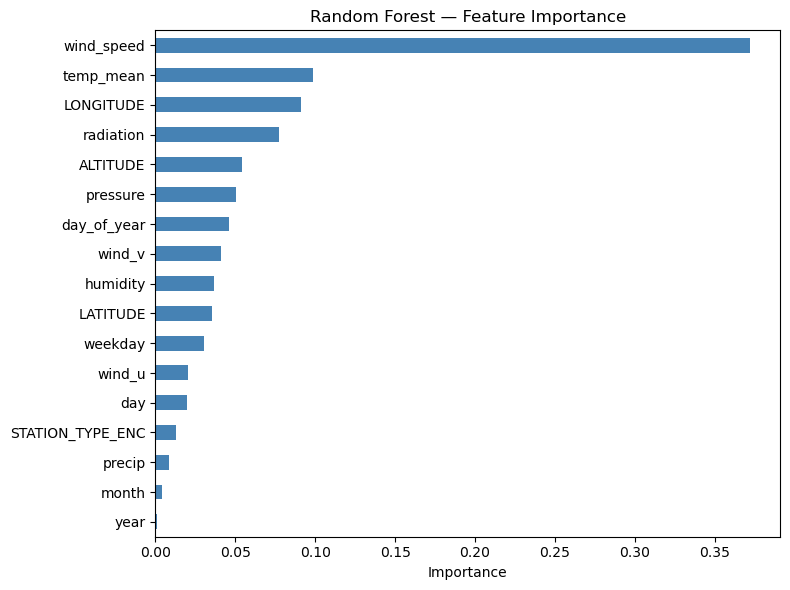

In [41]:
features_rf = [
    'LATITUDE', 'LONGITUDE', 'ALTITUDE', 'STATION_TYPE_ENC',
    'year', 'month', 'day', 'weekday', 'day_of_year',
    'temp_mean', 'wind_speed', 'wind_u', 'wind_v',
    'precip', 'pressure', 'humidity', 'radiation'
]

X_tab = df_sensor[features_rf]
y_tab = df_sensor['target_NO2']

X_train, X_test, y_train, y_test = train_test_split(
    X_tab, y_tab, test_size=0.2, random_state=42
)

from sklearn.ensemble import RandomForestRegressor
rf = RandomForestRegressor(n_estimators=150, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

mae_rf  = mean_absolute_error(y_test, y_pred_rf)
rmse_rf = mean_squared_error(y_test, y_pred_rf) ** 0.5
r2_rf   = r2_score(y_test, y_pred_rf)

print(f'Random Forest — MAE: {mae_rf:.2f} µg/m³  |  RMSE: {rmse_rf:.2f}  |  R²: {r2_rf:.3f}')


importances = pd.Series(rf.feature_importances_, index=features_rf).sort_values(ascending=True)
fig, ax = plt.subplots(figsize=(8, 6))
importances.plot(kind='barh', ax=ax, color='steelblue')
ax.set_title('Random Forest — Feature Importance')
ax.set_xlabel('Importance')
plt.tight_layout()
plt.savefig('outputs/rf_feature_importance.png', dpi=150)
plt.show()


It means:

Using only weather + location + time, the model can explain 91% of pollution behavior.

And it is wrong on average by only ~3 µg/m³.


# STEP 27 — SPATIO-TEMPORAL SEQUENCES

Reshape data into (days × stations) pivot, fuse with daily weather,
scale everything, then create sliding-window sequences.
Each sequence feeds SEQ_LEN=14 days of history → model predicts t+1, t+7, t+14. To look at the last 14 days of all stations + weather, and learn how pollution evolves

In [42]:
SEQ_LEN    = 14  
HORIZONS  = [1, 7, 14]   

df_daily = (
    dffinal_merged[['STATION_CODE','date','NO2_daily_mean']]
    .dropna(subset=['NO2_daily_mean'])
    .copy()
)

pivot_no2 = df_daily.pivot_table(
    index='date', columns='STATION_CODE', values='NO2_daily_mean'
)
pivot_no2 = pivot_no2.sort_index()
pivot_no2 = pivot_no2.interpolate(method='time').bfill().ffill()

n_stations = pivot_no2.shape[1]
print('NO₂ pivot shape (days × stations):', pivot_no2.shape)


df_meteo_idx = df_meteo.set_index('date').reindex(pivot_no2.index)
df_meteo_idx = df_meteo_idx.fillna(method='ffill').fillna(method='bfill')

meteo_feat_cols = ['temp_mean','wind_speed','wind_u','wind_v',
                   'precip','pressure','humidity','radiation']
n_meteo = len(meteo_feat_cols)


scaler_no2   = MinMaxScaler()
scaler_meteo = MinMaxScaler()

no2_scaled   = scaler_no2.fit_transform(pivot_no2.values)
meteo_scaled = scaler_meteo.fit_transform(df_meteo_idx[meteo_feat_cols].values)


data_full = np.concatenate([no2_scaled, meteo_scaled], axis=1)
print(f'Combined daily feature matrix: {data_full.shape}  '
      f'({n_stations} NO₂ channels + {n_meteo} weather channels)')


NO₂ pivot shape (days × stations): (423, 24)
Combined daily feature matrix: (423, 32)  (24 NO₂ channels + 8 weather channels)


C:\Users\farah\AppData\Local\Temp\ipykernel_24092\621465992.py:21: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df_meteo_idx = df_meteo_idx.fillna(method='ffill').fillna(method='bfill')


In [43]:


def create_multi_horizon_sequences(data, no2_only, seq_len, horizons):
    max_h   = max(horizons)
    n       = len(data) - seq_len - max_h + 1
    X_out   = np.zeros((n, seq_len, data.shape[1]))
    y_dict  = {h: np.zeros((n, no2_only.shape[1])) for h in horizons}
    for i in range(n):
        X_out[i] = data[i : i + seq_len]
        for h in horizons:
            y_dict[h][i] = no2_only[i + seq_len + h - 1]
    return X_out, y_dict

X_seq, y_dict = create_multi_horizon_sequences(
    data_full, no2_scaled, SEQ_LEN, HORIZONS
)

print(f'Sequence input shape:  {X_seq.shape}   (samples, time_steps, features)')
for h in HORIZONS:
    print(f'  Target t+{h:>2d}:  {y_dict[h].shape}')


Sequence input shape:  (396, 14, 32)   (samples, time_steps, features)
  Target t+ 1:  (396, 24)
  Target t+ 7:  (396, 24)
  Target t+14:  (396, 24)



# STEP 28 — CNN-LSTM MULTI-HORIZON MODEL

- **Conv1D** (TimeDistributed): spatial feature extraction per time step
- **LSTM**: temporal dynamics across the 14-day window
- **Three output heads**: t+1, t+7, t+14 forecasts simultaneously
- **Uncertainty**: MC-Dropout (run model N times at inference → std = uncertainty)

In [44]:
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Conv1D, LSTM, Dense, Dropout, Flatten

print('TensorFlow version:', tf.__version__)

n_features = X_seq.shape[2]

inp = Input(shape=(SEQ_LEN, n_features))

# ── Spatial extraction across the time sequence ───────────────────────────────
x = Conv1D(filters=64, kernel_size=3, activation='relu', padding='same')(inp)
x = Conv1D(filters=32, kernel_size=3, activation='relu', padding='same')(x)

# ── Temporal learning ─────────────────────────────────────────────────────────
x = LSTM(128, return_sequences=True, activation='tanh')(x)
x = Dropout(0.3)(x, training=True)   # MC-Dropout stays active at inference
x = LSTM(64, activation='tanh')(x)
x = Dropout(0.3)(x, training=True)

# ── Multi-horizon output heads ────────────────────────────────────────────────
out_t1  = Dense(n_stations, name='t_plus_1' )(x)
out_t7  = Dense(n_stations, name='t_plus_7' )(x)
out_t14 = Dense(n_stations, name='t_plus_14')(x)

cnn_lstm = Model(inputs=inp, outputs=[out_t1, out_t7, out_t14])
cnn_lstm.compile(
    optimizer='adam',
    loss={'t_plus_1':'mse', 't_plus_7':'mse', 't_plus_14':'mse'},
    loss_weights={'t_plus_1':1.0, 't_plus_7':0.8, 't_plus_14':0.6},
    metrics={'t_plus_1':'mae', 't_plus_7':'mae', 't_plus_14':'mae'}
)

cnn_lstm.summary()

TensorFlow version: 2.21.0


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)      │ (None, 14, 32)            │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv1d (Conv1D)               │ (None, 14, 64)            │           6,208 │ input_layer[0][0]          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv1d_1 (Conv1D)             │ (None, 14, 32)            │           6,176 │ conv1d[0][0]               │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ lstm (LSTM)                   │ (None, 14, 128)           │          82,432 │ conv1d_1[0][0]             │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dropout (Dropout)             │ (None, 14, 128)           │               0 │ lstm[0][0]                 │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ lstm_1 (LSTM)                 │ (None, 64)                │          49,408 │ dropout[0][0]              │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dropout_1 (Dropout)           │ (None, 64)                │               0 │ lstm_1[0][0]               │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ t_plus_1 (Dense)              │ (None, 24)                │           1,560 │ dropout_1[0][0]            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ t_plus_7 (Dense)              │ (None, 24)                │           1,560 │ dropout_1[0][0]            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ t_plus_14 (Dense)             │ (None, 24)                │           1,560 │ dropout_1[0][0]            │
└───────────────────────────────┴───────────────────────────┴─────────────────┴────────────────────────────┘

 Total params: 148,904 (581.66 KB)

 Trainable params: 148,904 (581.66 KB)

 Non-trainable params: 0 (0.00 B)

In [45]:
history = cnn_lstm.fit(
    X_seq,
    {'t_plus_1' : y_dict[1],
     't_plus_7' : y_dict[7],
     't_plus_14': y_dict[14]},
    epochs=40,
    batch_size=16,
    validation_split=0.2,
    verbose=1
)


Epoch 1/40
20/20 ━━━━━━━━━━━━━━━━━━━━ 6s 48ms/step - loss: 0.1443 - t_plus_14_loss: 0.0597 - t_plus_14_mae: 0.1874 - t_plus_1_loss: 0.0582 - t_plus_1_mae: 0.1839 - t_plus_7_loss: 0.0623 - t_plus_7_mae: 0.1937 - val_loss: 0.0970 - val_t_plus_14_loss: 0.0448 - val_t_plus_14_mae: 0.1629 - val_t_plus_1_loss: 0.0368 - val_t_plus_1_mae: 0.1479 - val_t_plus_7_loss: 0.0417 - val_t_plus_7_mae: 0.1518
Epoch 2/40
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.0877 - t_plus_14_loss: 0.0368 - t_plus_14_mae: 0.1486 - t_plus_1_loss: 0.0349 - t_plus_1_mae: 0.1422 - t_plus_7_loss: 0.0378 - t_plus_7_mae: 0.1482 - val_loss: 0.0882 - val_t_plus_14_loss: 0.0414 - val_t_plus_14_mae: 0.1521 - val_t_plus_1_loss: 0.0349 - val_t_plus_1_mae: 0.1399 - val_t_plus_7_loss: 0.0356 - val_t_plus_7_mae: 0.1398
Epoch 3/40
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.0749 - t_plus_14_loss: 0.0298 - t_plus_14_mae: 0.1316 - t_plus_1_loss: 0.0323 - t_plus_1_mae: 0.1364 - t_plus_7_loss: 0.0304 - t_plus_7_mae: 0.1330 -

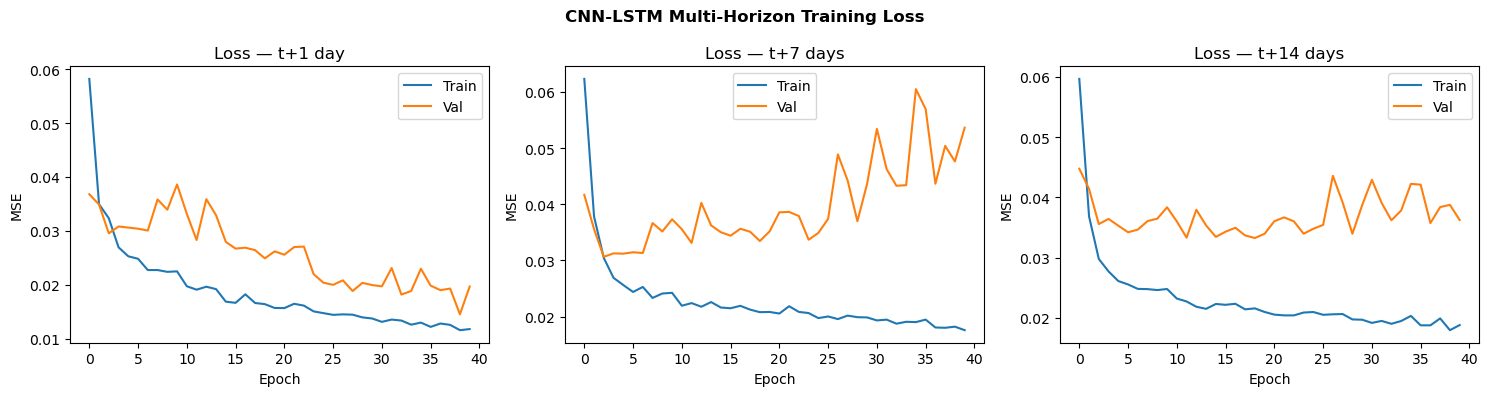

In [46]:

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
heads = ['t_plus_1', 't_plus_7', 't_plus_14']
titles = ['t+1 day', 't+7 days', 't+14 days']

for ax, head, title in zip(axes, heads, titles):
    ax.plot(history.history[f'{head}_loss'],     label='Train')
    ax.plot(history.history[f'val_{head}_loss'], label='Val')
    ax.set_title(f'Loss — {title}')
    ax.set_xlabel('Epoch')
    ax.set_ylabel('MSE')
    ax.legend()

plt.suptitle('CNN-LSTM Multi-Horizon Training Loss', fontweight='bold')
plt.tight_layout()
plt.savefig('outputs/cnn_lstm_training_loss.png', dpi=150)
plt.show()



# STEP 29 — UNCERTAINTY ESTIMATION (MC-Dropout)

Run the model N=50 times with dropout active at inference.
**Mean** = prediction,  **Std** = uncertainty (predictive uncertainty map).
This implements box 4.2 of the supervisor's diagram. To see How sure is the model about this prediction

In [47]:
N_MC = 50   

X_last = X_seq[-1:]

preds_t1  = np.zeros((N_MC, n_stations))
preds_t7  = np.zeros((N_MC, n_stations))
preds_t14 = np.zeros((N_MC, n_stations))

for i in range(N_MC):
    p1, p7, p14 = cnn_lstm(X_last, training=True)   # dropout ON
    preds_t1[i]  = p1.numpy()[0]
    preds_t7[i]  = p7.numpy()[0]
    preds_t14[i] = p14.numpy()[0]

# Inverse-scale
def inv(arr):
    # arr shape (N_MC, n_stations) → inverse via scaler_no2
    dummy = np.zeros((arr.shape[0], pivot_no2.shape[1]))
    dummy[:, :n_stations] = arr
    return scaler_no2.inverse_transform(dummy)[:, :n_stations]

mean_t1   = inv(preds_t1.mean(axis=0, keepdims=True))[0]
std_t1    = inv(preds_t1.std(axis=0,  keepdims=True))[0]
mean_t7   = inv(preds_t7.mean(axis=0, keepdims=True))[0]
std_t7    = inv(preds_t7.std(axis=0,  keepdims=True))[0]
mean_t14  = inv(preds_t14.mean(axis=0, keepdims=True))[0]
std_t14   = inv(preds_t14.std(axis=0,  keepdims=True))[0]

station_codes = list(pivot_no2.columns)

df_forecast = pd.DataFrame({
    'STATION_CODE' : station_codes,
    'NO2_t1_mean'  : mean_t1,   'NO2_t1_std'  : std_t1,
    'NO2_t7_mean'  : mean_t7,   'NO2_t7_std'  : std_t7,
    'NO2_t14_mean' : mean_t14,  'NO2_t14_std' : std_t14,
}).merge(dffinal_merged[['STATION_CODE','STATION_NAME',
                          'LATITUDE','LONGITUDE']].drop_duplicates(),
         on='STATION_CODE', how='left')

print(df_forecast[['STATION_NAME','NO2_t1_mean','NO2_t1_std',
                   'NO2_t7_mean','NO2_t14_mean']].to_string(index=False))


        STATION_NAME  NO2_t1_mean  NO2_t1_std  NO2_t7_mean  NO2_t14_mean
     Plaza de España    21.440179    8.199231    42.253734     32.544513
    Escuelas Aguirre    29.736525   14.467658    45.398431     39.630752
       Ramón y Cajal    27.416011   10.026916    43.592019     39.230982
        Arturo Soria    18.343082    8.920774    34.395128     30.628417
          Villaverde    29.225913   10.777432    47.905215     36.467801
           Farolillo    24.304050   10.254822    41.670030     34.062206
       Casa de Campo    11.905605    5.128621    30.340450     23.921075
      Barajas Pueblo    27.244057    8.550851    47.261715     43.015648
    Plaza del Carmen    24.923138    8.915829    42.701004     37.496872
           Moratalaz    23.917773    9.127825    43.629908     37.940293
      Cuatro Caminos    24.087020    8.310110    43.317922     36.290122
    Barrio del Pilar    27.220695    9.858324    40.074036     35.688408
            Vallecas    24.979163    9.965539    45

El Pardo → std = 2.2 (very certain)
Escuelas Aguirre → std = 14.8 (very uncertain)
 this means:
The model is confident in clean areas, uncertain in polluted complex areas.


# STEP 30 — PREDICTION MAPS  
Interpolate station forecasts over a spatial grid using Kriging.
Produces one NO₂ prediction map per horizon + one uncertainty map.

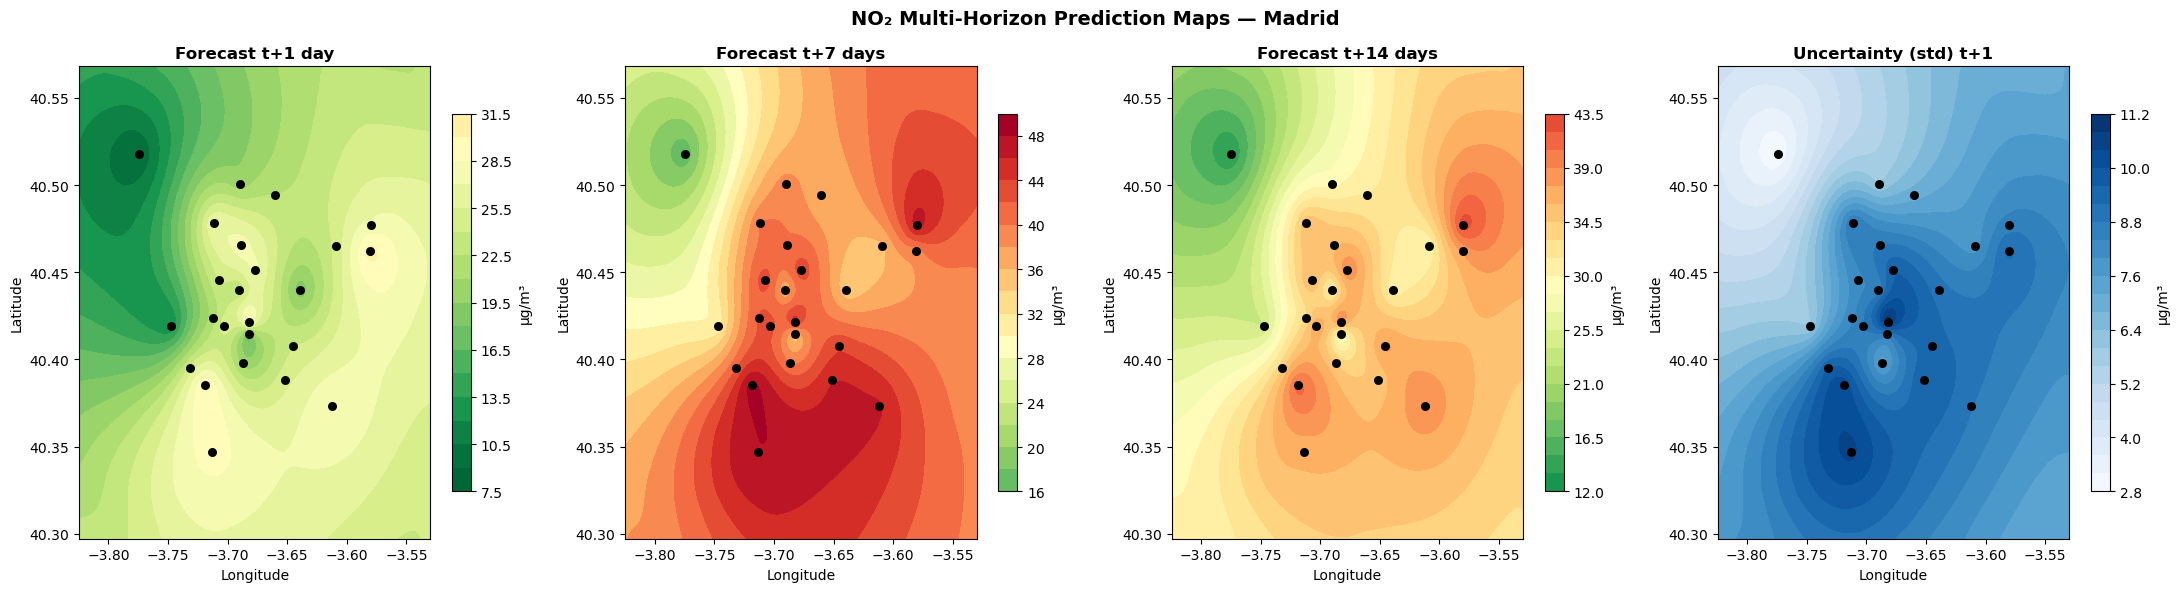

✅ Prediction maps saved


In [48]:
from pykrige.ok import OrdinaryKriging
from scipy.interpolate import griddata

# Station coordinates (geographic degrees)
lons_st = df_forecast['LONGITUDE'].values
lats_st = df_forecast['LATITUDE'].values

lon_grid = np.linspace(lons_st.min()-0.05, lons_st.max()+0.05, 120)
lat_grid = np.linspace(lats_st.min()-0.05, lats_st.max()+0.05, 120)

def kriging_map(values, lons, lats, lon_g, lat_g):
    ok = OrdinaryKriging(lons, lats, values,
                         variogram_model='spherical',
                         verbose=False, enable_plotting=False)
    z, _ = ok.execute('grid', lon_g, lat_g)
    return z

grid_t1  = kriging_map(df_forecast['NO2_t1_mean'],  lons_st, lats_st, lon_grid, lat_grid)
grid_t7  = kriging_map(df_forecast['NO2_t7_mean'],  lons_st, lats_st, lon_grid, lat_grid)
grid_t14 = kriging_map(df_forecast['NO2_t14_mean'], lons_st, lats_st, lon_grid, lat_grid)
grid_unc = kriging_map(df_forecast['NO2_t1_std'],   lons_st, lats_st, lon_grid, lat_grid)

LON_G, LAT_G = np.meshgrid(lon_grid, lat_grid)

vmin = min(grid_t1.min(), grid_t7.min(), grid_t14.min())
vmax = max(grid_t1.max(), grid_t7.max(), grid_t14.max())

fig, axes = plt.subplots(1, 4, figsize=(22, 6))
maps   = [grid_t1, grid_t7, grid_t14, grid_unc]
titles = ['Forecast t+1 day', 'Forecast t+7 days',
          'Forecast t+14 days', 'Uncertainty (std) t+1']
cmaps  = ['RdYlGn_r','RdYlGn_r','RdYlGn_r','Blues']
vmins  = [vmin, vmin, vmin, None]
vmaxs  = [vmax, vmax, vmax, None]

for ax, grd, title, cmap, vmn, vmx in zip(
        axes, maps, titles, cmaps, vmins, vmaxs):
    kwargs = dict(levels=20, cmap=cmap)
    if vmn is not None:
        kwargs.update(vmin=vmn, vmax=vmx)
    cf = ax.contourf(LON_G, LAT_G, grd, **kwargs)
    ax.scatter(lons_st, lats_st, c='black', s=30, zorder=5)
    plt.colorbar(cf, ax=ax, shrink=0.8, label='µg/m³')
    ax.set_title(title, fontweight='bold')
    ax.set_xlabel('Longitude')
    ax.set_ylabel('Latitude')

plt.suptitle('NO₂ Multi-Horizon Prediction Maps — Madrid', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('outputs/prediction_maps.png', dpi=150, bbox_inches='tight')
plt.show()
print('✅ Prediction maps saved')



# STEP 31 — RISK / ANOMALY MAP  (box 4.3)

EU air-quality thresholds for NO₂ (daily mean, µg/m³):
- **Faible  (Low)**     : < 40 µg/m³
- **Moyen   (Medium)**  : 40 – 100 µg/m³
- **Critique (High)**   : > 100 µg/m³

Applied to the t+1 forecast grid.

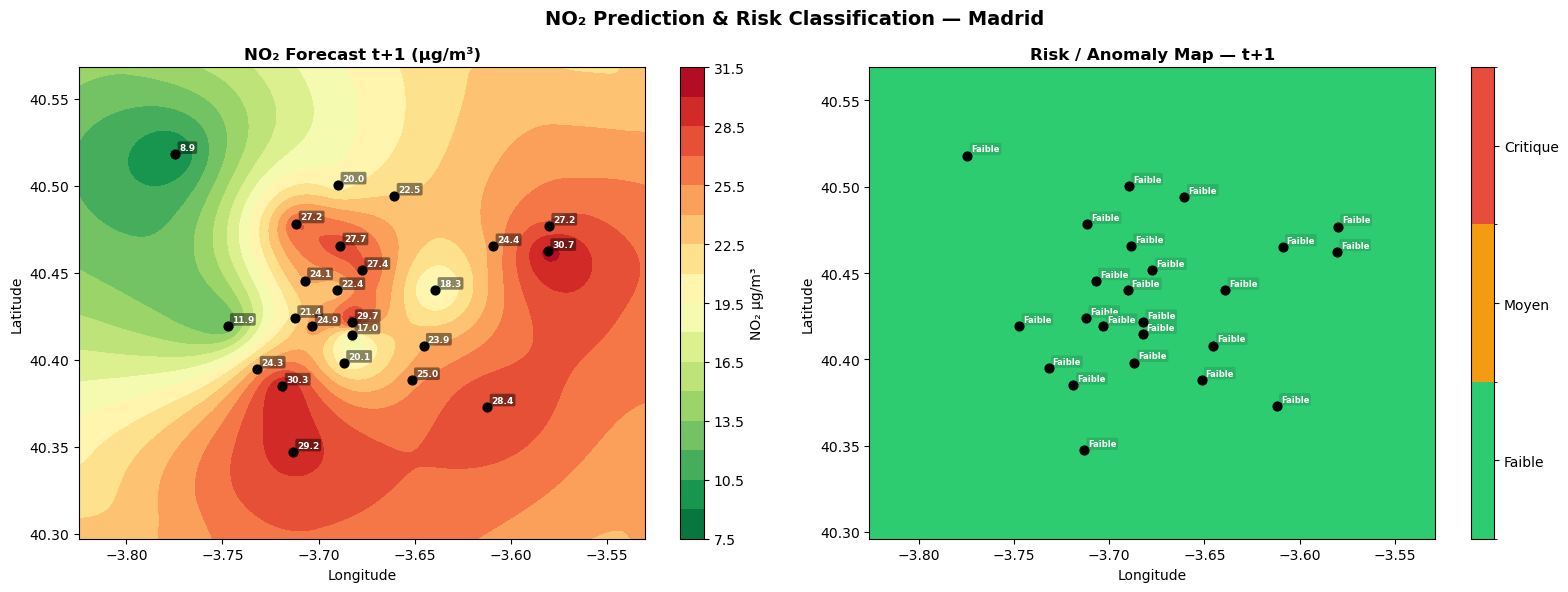


Station Risk Summary:
        STATION_NAME  NO2_t1_mean   risk
       Urb. Embajada    30.689671 Faible
      Plaza Elíptica    30.316964 Faible
    Escuelas Aguirre    29.736525 Faible
          Villaverde    29.225913 Faible
Ensanche de Vallecas    28.439885 Faible
      Plaza Castilla    27.710566 Faible
       Ramón y Cajal    27.416011 Faible
      Barajas Pueblo    27.244057 Faible
    Barrio del Pilar    27.220695 Faible
            Vallecas    24.979163 Faible
    Plaza del Carmen    24.923138 Faible
       Juan Carlos I    24.439691 Faible
           Farolillo    24.304050 Faible
      Cuatro Caminos    24.087020 Faible
           Moratalaz    23.917773 Faible
         Sanchinarro    22.523742 Faible
          Castellana    22.395190 Faible
     Plaza de España    21.440179 Faible
       Méndez Álvaro    20.100596 Faible
         Tres Olivos    19.994261 Faible
        Arturo Soria    18.343082 Faible
   Parque del Retiro    16.981314 Faible
       Casa de Campo    11.905605 

In [49]:
import matplotlib.colors as mcolors


THRESH_LOW  = 40    
THRESH_HIGH = 100   

# Classify each grid cell
risk = np.zeros_like(grid_t1.data, dtype=int)
risk[grid_t1.data > THRESH_LOW]  = 1   # Moyen
risk[grid_t1.data > THRESH_HIGH] = 2   # Critique

# Station-level risk
def classify_risk(val):
    if val > THRESH_HIGH: return 'Critique'
    if val > THRESH_LOW:  return 'Moyen'
    return 'Faible'

df_forecast['risk'] = df_forecast['NO2_t1_mean'].apply(classify_risk)

# Plot
cmap_risk  = mcolors.ListedColormap(['#2ecc71','#f39c12','#e74c3c'])
bounds     = [-0.5, 0.5, 1.5, 2.5]
norm_risk  = mcolors.BoundaryNorm(bounds, cmap_risk.N)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# ── Left: continuous NO₂ forecast ────────────────────────────────────────────
cf1 = axes[0].contourf(LON_G, LAT_G, grid_t1, levels=20, cmap='RdYlGn_r')
axes[0].scatter(lons_st, lats_st, c='black', s=40, zorder=5)
for _, row in df_forecast.iterrows():
    axes[0].annotate(f"{row['NO2_t1_mean']:.1f}",
                     xy=(row['LONGITUDE'], row['LATITUDE']),
                     xytext=(3,3), textcoords='offset points',
                     fontsize=6.5, color='white', fontweight='bold',
                     bbox=dict(boxstyle='round,pad=0.2',
                               facecolor='black', alpha=0.45, edgecolor='none'))
plt.colorbar(cf1, ax=axes[0], label='NO₂ µg/m³')
axes[0].set_title('NO₂ Forecast t+1 (µg/m³)', fontweight='bold')
axes[0].set_xlabel('Longitude'); axes[0].set_ylabel('Latitude')

# ── Right: risk classification ────────────────────────────────────────────────
cf2 = axes[1].pcolormesh(LON_G, LAT_G, risk,
                          cmap=cmap_risk, norm=norm_risk, shading='auto')
axes[1].scatter(lons_st, lats_st, c='black', s=40, zorder=5)
for _, row in df_forecast.iterrows():
    color = {'Faible':'#27ae60','Moyen':'#e67e22','Critique':'#c0392b'}[row['risk']]
    axes[1].annotate(row['risk'],
                     xy=(row['LONGITUDE'], row['LATITUDE']),
                     xytext=(3,3), textcoords='offset points',
                     fontsize=6, color='white', fontweight='bold',
                     bbox=dict(boxstyle='round,pad=0.2',
                               facecolor=color, alpha=0.8, edgecolor='none'))
cbar2 = plt.colorbar(cf2, ax=axes[1], ticks=[0,1,2])
cbar2.ax.set_yticklabels(['Faible','Moyen','Critique'])
axes[1].set_title('Risk / Anomaly Map — t+1', fontweight='bold')
axes[1].set_xlabel('Longitude'); axes[1].set_ylabel('Latitude')

plt.suptitle('NO₂ Prediction & Risk Classification — Madrid', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('outputs/risk_map.png', dpi=150, bbox_inches='tight')
plt.show()

print('\nStation Risk Summary:')
print(df_forecast[['STATION_NAME','NO2_t1_mean','risk']]
      .sort_values('NO2_t1_mean', ascending=False).to_string(index=False))



# STEP 32 — MODEL EVALUATION & COMPARISON

Evaluate CNN-LSTM on all three horizons and compare with Random Forest baseline.

               MAE (µg/m³)  RMSE (µg/m³)     R²
CNN-LSTM t+1         5.790         7.721  0.559
CNN-LSTM t+7         7.885        10.372  0.161
CNN-LSTM t+14        7.640         9.816  0.262
Random Forest        2.896         3.967  0.911


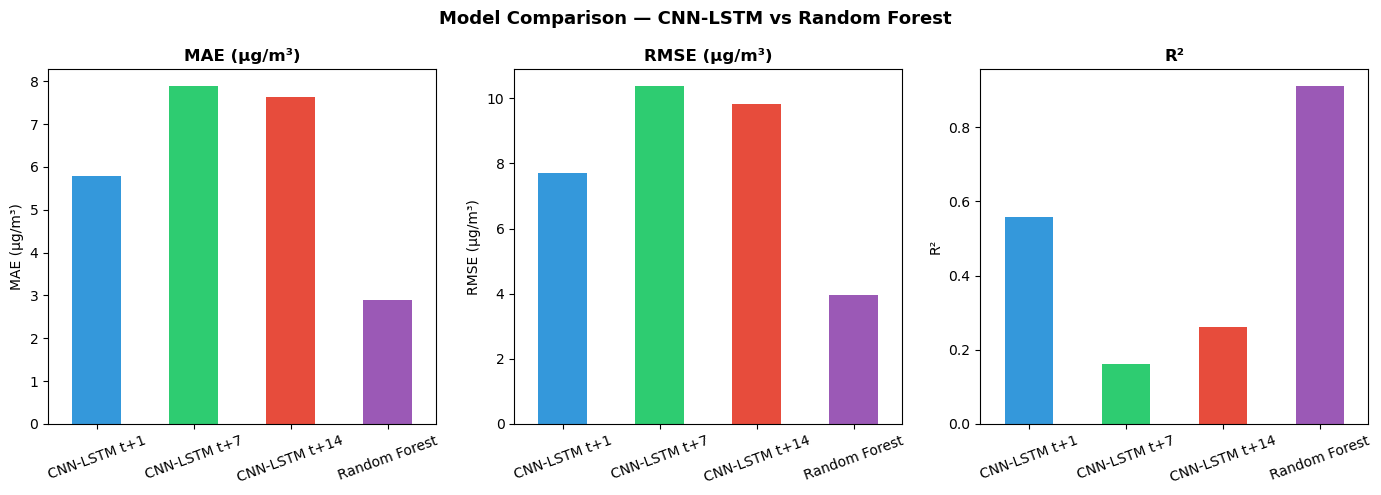


✅ Evaluation complete. All outputs saved to outputs/


In [50]:
# ── CNN-LSTM predictions on full dataset ─────────────────────────────────────
pred_t1, pred_t7, pred_t14 = cnn_lstm.predict(X_seq, verbose=0)

def inv_no2(arr):
    dummy = np.zeros((arr.shape[0], pivot_no2.shape[1]))
    dummy[:, :arr.shape[1]] = arr
    return scaler_no2.inverse_transform(dummy)[:, :arr.shape[1]]

results = {}
for tag, pred, true in [
    ('CNN-LSTM t+1',  pred_t1,  y_dict[1]),
    ('CNN-LSTM t+7',  pred_t7,  y_dict[7]),
    ('CNN-LSTM t+14', pred_t14, y_dict[14]),
]:
    p_inv = inv_no2(pred)
    t_inv = inv_no2(true)
    results[tag] = {
        'MAE (µg/m³)' : mean_absolute_error(t_inv, p_inv),
        'RMSE (µg/m³)': mean_squared_error(t_inv, p_inv)**0.5,
        'R²'          : r2_score(t_inv, p_inv),
    }

results['Random Forest'] = {
    'MAE (µg/m³)' : mae_rf,
    'RMSE (µg/m³)': rmse_rf,
    'R²'          : r2_rf,
}

df_eval = pd.DataFrame(results).T.round(3)
print(df_eval.to_string())

# Bar chart
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
for ax, metric in zip(axes, ['MAE (µg/m³)','RMSE (µg/m³)','R²']):
    colors = ['#3498db','#2ecc71','#e74c3c','#9b59b6']
    df_eval[metric].plot(kind='bar', ax=ax, color=colors, rot=20)
    ax.set_title(metric, fontweight='bold')
    ax.set_ylabel(metric)

plt.suptitle('Model Comparison — CNN-LSTM vs Random Forest', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('outputs/model_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print('\n✅ Evaluation complete. All outputs saved to outputs/')


It means Weather explains pollution well for the present,
but forecasting pollution many days ahead is very hard.

Tomorrow’s pollution is still very similar to today because:
Weather changes slowly from one day to the next
Pollution has inertia (it doesn’t jump randomly)
Traffic patterns are similar
Atmospheric conditions are similar